# Computational Linear Algebra: PCA Homework

## Exercise 0.0: Initialization
Fill the missing values in this text box. **Remove the information of the second student if you are not working in a team**.

**Academic Year:** 2025/2026

### Team Members (Alphabetical Order):
1. Biancone, Arianna Giulia (354965);
2. Ivaldi, Ludovica (355199);

Now, fill the python list below with the Student IDs of the team

In [1]:
StudentIDs = [355199,354965]  # <-------- Fill this list with Student IDs of the team

## Exercise 0.1: Starting Code-Cell

Download the .csv files from the web page of the course (*responses_hw.csv* and *columns_hw.csv*) and past them in **the same folder of this notebook**.


Then, run the cell below, **without modifing any line of code**.

The output of this code cell is **your personal subset of the original dataset**, with 2/3 of the original features (i.e., columns) and 3/4 of the original persons (i.e., rows).

### ATTENTION: DO NOT CHANGE THE CODE INSIDE THE FOLLOWING CELL, ANY CHANGE CAN INVALIDATE THE HOMEWORK!

In [2]:
####################################################################
############## DO NOT CHANGE THE CODE IN THIS CELL #################
####################################################################

import numpy as np
import pandas as pd
from IPython.display import display

var_entertainment_feat_types = ['Interests', 'Movies', 'Music']
var_personal_feat_types = ['Finance', 'Phobias']
fixed_feat_types = ['Personality', 'Health']

label_types = ['Demographic']

variables_by_type = {
    'Demographics': ['Age', 'Height', 'Weight', 'Number of siblings',
                     'Gender', 'Hand', 'Education', 'Only child', 'Home Town Type',
                     'Home Type'],
    'Finance': ['Finances', 'Shopping centres', 'Branded clothing',
                'Entertainment spending', 'Spending on looks',
                'Spending on gadgets', 'Spending on healthy eating'],
    'Health': ['Smoking', 'Alcohol', 'Healthy eating'],
    'Interests': ['History', 'Psychology', 'Politics', 'Mathematics',
                  'Physics', 'Internet', 'PC', 'Economy Management',
                  'Biology', 'Chemistry', 'Reading', 'Geography',
                  'Foreign languages', 'Medicine', 'Law', 'Cars',
                  'Art exhibitions', 'Religion', 'Countryside, outdoors',
                  'Dancing', 'Musical instruments', 'Writing', 'Passive sport',
                  'Active sport', 'Gardening', 'Celebrities', 'Shopping',
                  'Science and technology', 'Theatre', 'Fun with friends',
                  'Adrenaline sports', 'Pets'],
    'Movies': ['Movies', 'Horror', 'Thriller', 'Comedy', 'Romantic',
               'Sci-fi', 'War', 'Fantasy/Fairy tales', 'Animated',
               'Documentary', 'Western', 'Action'],
    'Music': ['Music', 'Slow songs or fast songs', 'Dance', 'Folk',
              'Country', 'Classical music', 'Musical', 'Pop', 'Rock',
              'Metal or Hardrock', 'Punk', 'Hiphop, Rap', 'Reggae, Ska',
              'Swing, Jazz', 'Rock n roll', 'Alternative', 'Latino',
              'Techno, Trance', 'Opera'],
    'Personality': ['Daily events', 'Prioritising workload',
                    'Writing notes', 'Workaholism', 'Thinking ahead',
                    'Final judgement', 'Reliability', 'Keeping promises',
                    'Loss of interest', 'Friends versus money', 'Funniness',
                    'Fake', 'Criminal damage', 'Decision making', 'Elections',
                    'Self-criticism', 'Judgment calls', 'Hypochondria',
                    'Empathy', 'Eating to survive', 'Giving',
                    'Compassion to animals', 'Borrowed stuff',
                    'Loneliness', 'Cheating in school', 'Health',
                    'Changing the past', 'God', 'Dreams', 'Charity',
                    'Number of friends', 'Punctuality', 'Lying', 'Waiting',
                    'New environment', 'Mood swings', 'Appearence and gestures',
                    'Socializing', 'Achievements', 'Responding to a serious letter',
                    'Children', 'Assertiveness', 'Getting angry',
                    'Knowing the right people', 'Public speaking',
                    'Unpopularity', 'Life struggles', 'Happiness in life',
                    'Energy levels', 'Small - big dogs', 'Personality',
                    'Finding lost valuables', 'Getting up', 'Interests or hobbies',
                    "Parents' advice", 'Questionnaires or polls', 'Internet usage'],
    'Phobias': ['Flying', 'Storm', 'Darkness', 'Heights', 'Spiders', 'Snakes',
                'Rats', 'Ageing', 'Dangerous dogs', 'Fear of public speaking']
}

labels = variables_by_type['Demographics']
features_all = []
for tt in variables_by_type.keys():
    if tt != 'Demographics':
        features_all += variables_by_type[tt]

def which_features(*StudentIDs):
    random_seed = min(StudentIDs)
    np.random.seed(random_seed)
    features_ = np.random.choice(features_all, int((2 * len(features_all)) / 3), replace=False).tolist()
    features = []
    features_by_type = {tt: [] for tt in variables_by_type.keys() if tt != 'Demographics'}
    for tt in variables_by_type.keys():
        ft_list = variables_by_type[tt]
        for ii in range(len(ft_list)):
            if ft_list[ii] in features_:
                features.append(ft_list[ii])
                features_by_type[tt].append(ft_list[ii])

    return features, features_by_type

features, features_by_type = which_features(*StudentIDs)

print(f'*** THESE ARE THE {len(features)} SELECTED FEATURES (SEE VARIABLE features):')
for ff in features:
    print(f'{ff}')
print('*************************************')
print('')
print('*** SELECTED FEATURES BY TYPES (SEE VARIABLE features_by_type):')
for tt in features_by_type.keys():
    print(f'{tt}: {features_by_type[tt]}')
    print('')
print('*************************************')
print('')
print('*** THESE ARE THE LABELS (SEE VARIABLE labels):')
for ll in labels:
    print(f'{ll}')
print('*************************************')

def which_rows(df, frac, *StudentIDs):
    random_seed = min(StudentIDs)
    df_ = df.sample(frac=frac, random_state=random_seed)
    return df_

responses_hw = pd.read_csv('responses_hw.csv', index_col=0)
responses = which_rows(responses_hw, 0.75, *StudentIDs)
responses = responses.loc[:, features + labels]

responses_ft = responses.loc[:, features]
responses_lb = responses.loc[:, labels]

print('')
print('*** THIS IS YOUR PERSONAL DATASET (features AND labels TOGETHER, SEE VARIABLE responses)')
display(responses)
print('')
print('*** THIS IS YOUR PERSONAL DATASET (features, SEE VARIABLE responses_ft)')
display(responses_ft)
print('')
print('*** THIS IS YOUR PERSONAL DATASET (labels, SEE VARIABLE responses_lb)')
display(responses_lb)

random_seed = min(StudentIDs)
np.random.seed(random_seed)

your_scaler = np.random.choice(['StandardScaler', 'MinMaxScaler'])


*** THESE ARE THE 93 SELECTED FEATURES (SEE VARIABLE features):
Shopping centres
Branded clothing
Spending on looks
Spending on gadgets
Spending on healthy eating
Smoking
Alcohol
Healthy eating
History
Politics
Mathematics
Internet
Economy Management
Biology
Geography
Medicine
Law
Cars
Art exhibitions
Religion
Countryside, outdoors
Musical instruments
Writing
Passive sport
Gardening
Shopping
Science and technology
Theatre
Fun with friends
Adrenaline sports
Pets
Horror
War
Fantasy/Fairy tales
Animated
Documentary
Western
Slow songs or fast songs
Country
Classical music
Rock
Metal or Hardrock
Punk
Hiphop, Rap
Swing, Jazz
Techno, Trance
Prioritising workload
Writing notes
Thinking ahead
Final judgement
Reliability
Keeping promises
Loss of interest
Friends versus money
Funniness
Decision making
Self-criticism
Compassion to animals
Borrowed stuff
Health
Changing the past
God
Dreams
Number of friends
Punctuality
Lying
Waiting
Mood swings
Socializing
Responding to a serious letter
Children
As

,Shopping centres,Branded clothing,Spending on looks,Spending on gadgets,Spending on healthy eating,Smoking,Alcohol,Healthy eating,History,Politics,...,Age,Height,Weight,Number of siblings,Gender,Hand,Education,Only child,Home Town Type,Home Type
327,4,2,3,2,4,never smoked,social drinker,4,1,2,...,19,175,58,1,female,right,secondary school,no,village,house/bungalow
141,4,4,4,4,5,tried smoking,social drinker,3,4,2,...,20,169,64,0,female,right,secondary school,yes,city,block of flats
587,3,3,3,4,4,never smoked,social drinker,4,4,4,...,25,172,56,1,female,right,masters degree,no,city,block of flats
258,5,1,1,1,5,tried smoking,social drinker,3,4,1,...,19,166,58,1,female,right,college/bachelor degree,no,village,house/bungalow
484,3,1,2,1,4,tried smoking,social drinker,3,3,1,...,22,170,55,1,female,right,secondary school,no,village,block of flats
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
593,3,2,3,3,4,never smoked,social drinker,3,4,5,...,22,189,89,2,male,right,secondary school,no,city,house/bungalow
4,3,3,1,4,4,never smoked,never,2,5,4,...,20,186,77,1,male,right,secondary school,no,city,block of flats
28,3,4,3,1,2,tried smoking,social drinker,3,4,4,...,20,177,67,5,male,right,college/bachelor degree,no,city,block of flats
295,5,4,3,4,4,tried smoking,social drinker,3,4,3,...,18,167,56,2,male,right,college/bachelor degree,no,city,block of flats



*** THIS IS YOUR PERSONAL DATASET (features, SEE VARIABLE responses_ft)


,Shopping centres,Branded clothing,Spending on looks,Spending on gadgets,Spending on healthy eating,Smoking,Alcohol,Healthy eating,History,Politics,...,Questionnaires or polls,Internet usage,Flying,Storm,Darkness,Spiders,Snakes,Rats,Ageing,Fear of public speaking
327,4,2,3,2,4,never smoked,social drinker,4,1,2,...,3,less than an hour a day,3,5,5,4,5,5,2,5
141,4,4,4,4,5,tried smoking,social drinker,3,4,2,...,3,few hours a day,2,2,3,4,5,4,2,3
587,3,3,3,4,4,never smoked,social drinker,4,4,4,...,4,few hours a day,2,1,1,5,4,3,3,5
258,5,1,1,1,5,tried smoking,social drinker,3,4,1,...,5,less than an hour a day,2,2,4,1,2,4,5,1
484,3,1,2,1,4,tried smoking,social drinker,3,3,1,...,3,few hours a day,3,2,4,2,5,4,1,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
593,3,2,3,3,4,never smoked,social drinker,3,4,5,...,3,few hours a day,1,1,1,1,1,1,2,3
4,3,3,1,4,4,never smoked,never,2,5,4,...,4,few hours a day,3,2,2,1,2,2,1,3
28,3,4,3,1,2,tried smoking,social drinker,3,4,4,...,2,few hours a day,1,2,2,2,2,2,1,3
295,5,4,3,4,4,tried smoking,social drinker,3,4,3,...,4,few hours a day,1,2,3,4,4,4,1,1



*** THIS IS YOUR PERSONAL DATASET (labels, SEE VARIABLE responses_lb)


,Age,Height,Weight,Number of siblings,Gender,Hand,Education,Only child,Home Town Type,Home Type
327,19,175,58,1,female,right,secondary school,no,village,house/bungalow
141,20,169,64,0,female,right,secondary school,yes,city,block of flats
587,25,172,56,1,female,right,masters degree,no,city,block of flats
258,19,166,58,1,female,right,college/bachelor degree,no,village,house/bungalow
484,22,170,55,1,female,right,secondary school,no,village,block of flats
...,...,...,...,...,...,...,...,...,...,...
593,22,189,89,2,male,right,secondary school,no,city,house/bungalow
4,20,186,77,1,male,right,secondary school,no,city,block of flats
28,20,177,67,5,male,right,college/bachelor degree,no,city,block of flats
295,18,167,56,2,male,right,college/bachelor degree,no,city,block of flats


## Exercise 0.2: Importing Modules

In the following cell, import all the modules you think are necessary for doing the homework, **among the ones listed and used during the laboratories of the course**.

For reproducibility, **no extra modules are allowed**.

**DO NOT IMPORT NUMPY NOR PANDAS**, they are already imported.

In [3]:
# DO NOT IMPORT NUMPY AND PANDAS - Already imported
import sklearn
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
#%matplotlib widget


## Exercise 1. Dataset Preprocessing

In this exercise, you have to do the following operations on the dataset of the features **responses_ft**:
1. Create a new dataframe called **responses_ft_enc** by encoding the categorical features (if they exist), motivating your choices;
1. Create a new dataframe called **responses_ft_pp** by preprocessing the data in **responses_ft_enc**, according to the scaler reported in the cell below.

In [4]:
print(f'*** YOU HAVE TO APPLY A PREPROCESSING USING THE {your_scaler}')

*** YOU HAVE TO APPLY A PREPROCESSING USING THE StandardScaler


For doing this exercise, fill the cells below following the instructions you read.

#### Describe and motivate the encoding operations you will apply (max 150 words):
We apply an **Ordinal Encoder** to all categorical features because their categories have an **intrinsic order**. Assigning ordered numerical values preserves this structure and allows PCA to interpret increasing or decreasing patterns across features. Without encoding, PCA cannot process non-numerical data, and using an ordinal approach **prevents the loss of information** that would occur with one-hot encoding in this specific context, where the order of responses is meaningful.

#### Describe the preprocessing operation you will apply and comment the effects it may have on the data (max 150 words):
We apply a **Standard Scaler** so that each feature has mean 0 and variance 1, which is equivalent to performing PCA on the **correlation matrix**. Standardization is necessary because variables use different ranges: most features span 1–5, while ordinal-encoded variables use smaller ranges (e.g., 0–2 or 0-3). By placing all features on a comparable scale, we ensure that the principal components capture **relationships among variables** rather than **differences in measurement units**.

However, a potential drawback is that it redistributes variance equally, treating all variables as equally informative. This can amplify noise from low-variance features, **potentially requiring more components** to explain the total variance. In this context, **Min-Max Scaling** could be considered more suitable, as it would preserve relative variance differences. Nevertheless, since our features already operate within similar orders of magnitude, StandardScaler remains an appropriate choice, allowing PCA to identify patterns driven by correlation rather than raw scale.

#### Write the code for performing the encoding and preprocessing operations of the exercise. Show the encoded data and the preprocessed data you obtain, plus any additional table/value that can be useful for commenting the results:

In [5]:
cat = responses_ft.select_dtypes('object')
order=[['never smoked','tried smoking','former smoker','current smoker'],
       ['never','social drinker','drink a lot'],
       ['early','on time','late'],
       ['never','only to avoid hurting someone','sometimes','everytime it suits me'],
       ['less than an hour a day','few hours a day','most of the day']]
od=OrdinalEncoder(categories=order)
cat_enc=od.fit_transform(cat)
responses_ft_enc= responses_ft.copy()
responses_ft_enc[cat.columns]=cat_enc

ss=StandardScaler()
responses_ft_pp=ss.fit_transform(responses_ft_enc)
responses_ft_pp=pd.DataFrame(responses_ft_pp,columns=responses_ft_enc.columns)

#### Comment the results obtained after the preprocessing operation (max 100 words):
After preprocessing, all features have mean 0 and variance 1, ensuring that **no variable dominates the PCA due to scale differences**. The categorical features, previously non-numerical, are now encoded as ordered numerical values that reflect their inherent ranking. As a result, all columns contribute comparably to the total variance, and **PCA can meaningfully capture patterns** and relationships across both original **numerical** variables and encoded **categorical** ones.

## Exercise 2. Analyzing the Variance and the PCs

In this exercise, you have to do the following operations:
1. compute and visualize the variance of all the features in *responses_ft_enc* and *responses_ft_pp*;
1. compute all the $n$ Principal Components (PCs) for *responses_ft_enc* and *responses_ft_pp*, separately, and visualize the curves of the cumulative explained variances.

For doing this exercise, fill the cells below following the instructions you read.

#### Write the code for computing and visualizing the variance of the features of the two datasets:

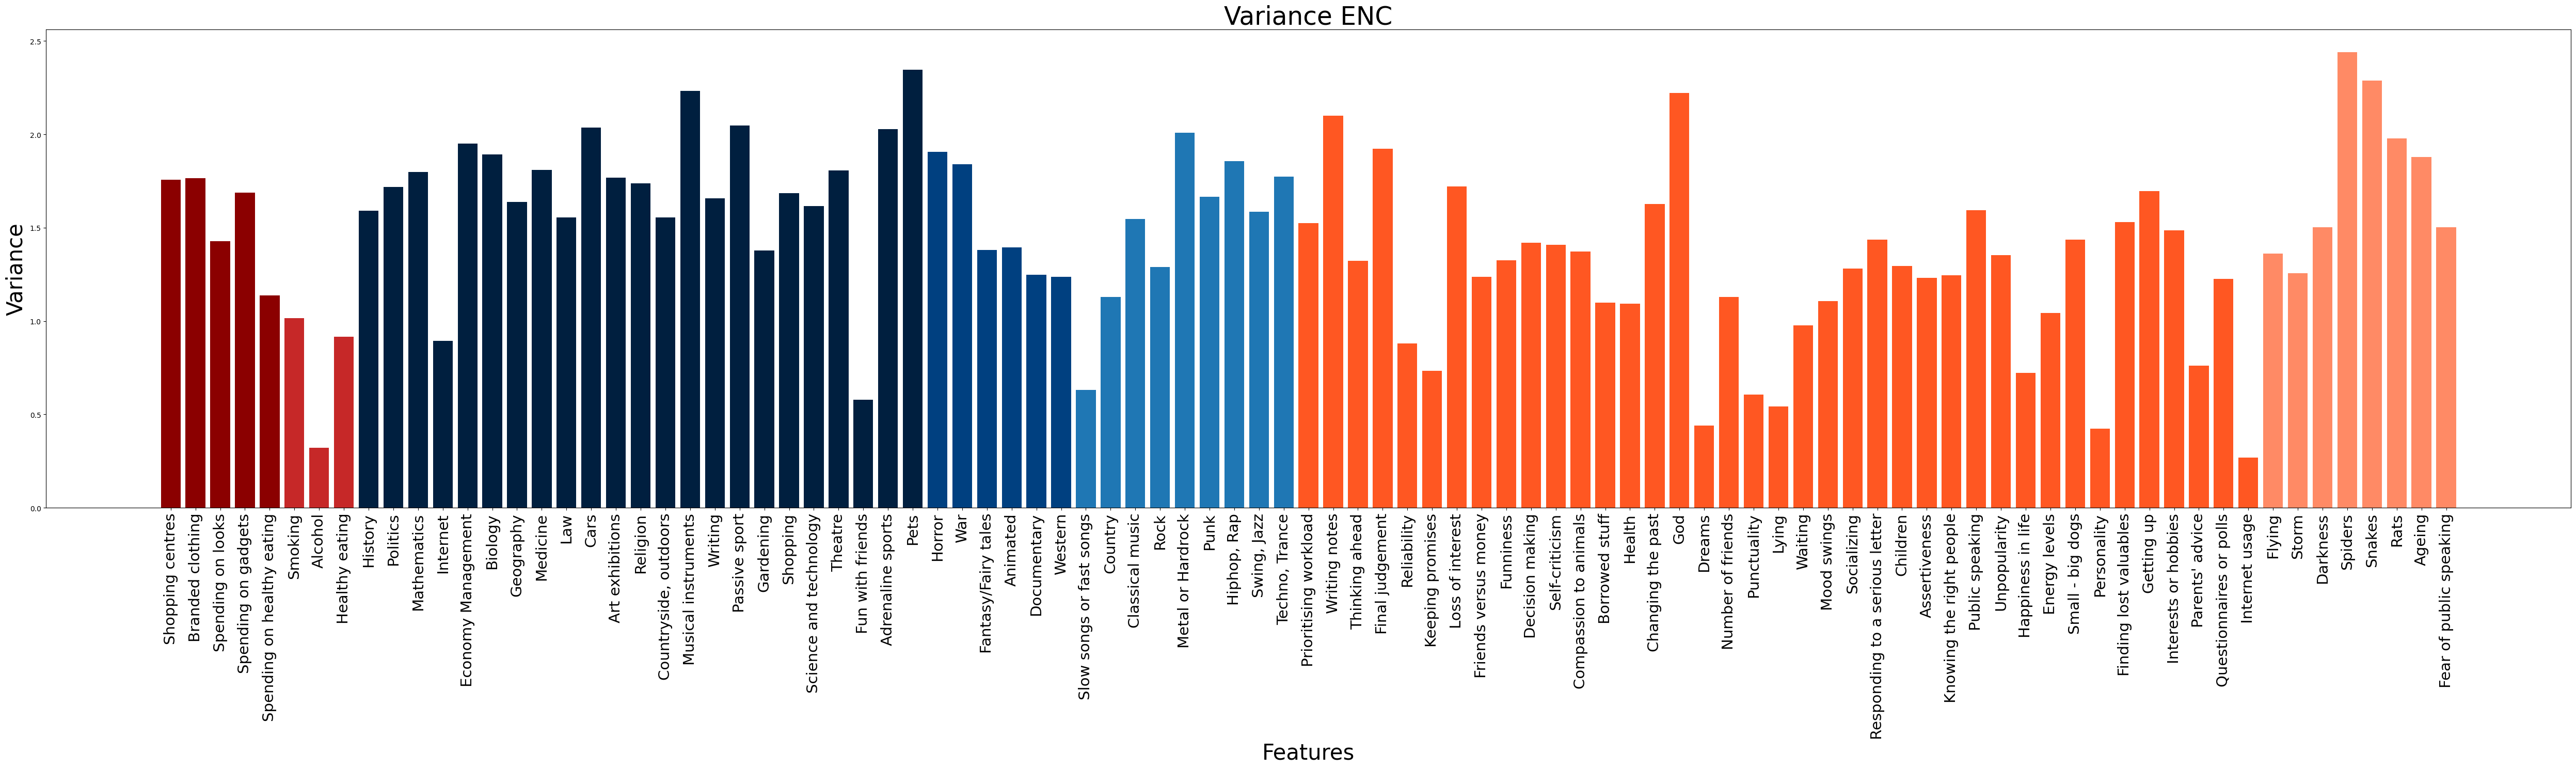

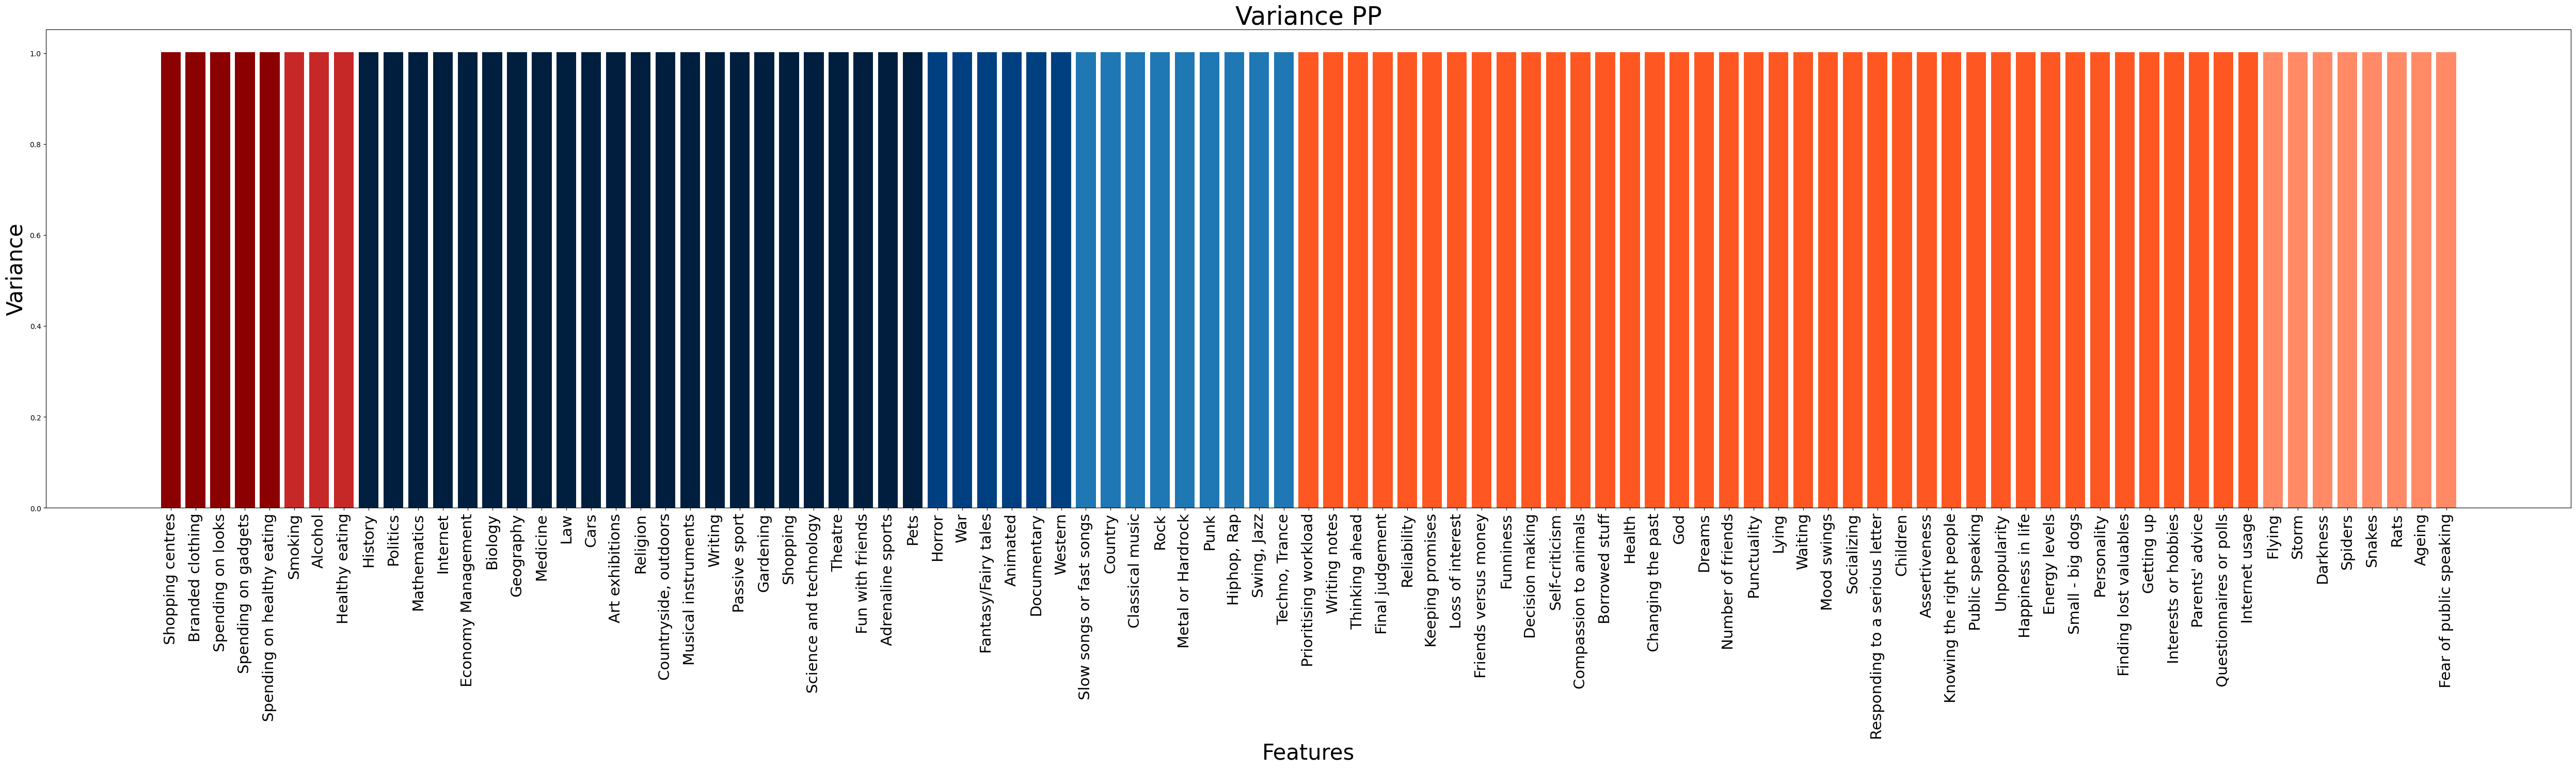

In [6]:
#Create a customized color palette --> warm colors for personality aspects and cool colors for entertainment.

warm_colors = {'Finance':     '#8B0000',
               'Health':      '#C62828',
               'Personality': '#FF5722',
               'Phobias':     '#FF8A65'}

cool_colors = {
    'Interests': '#001f3f',
    'Movies':    '#004080',
    'Music':     '#1f77b4'  }

default_color = 'lightgray'   # for Demographics (

def build_color_map(columns):
    """Function that creates a map between features and colors"""
    color_map = []
    for col in columns:
        assigned = False
        for cat, feats in variables_by_type.items():
            if col in feats:
                if cat in warm_colors:
                    color_map.append(warm_colors[cat])
                elif cat in cool_colors:
                    color_map.append(cool_colors[cat])
                else:
                    color_map.append(default_color)
                assigned = True
                break
        if not assigned:
            color_map.append(default_color)
    return color_map


# GRAPH AFTER ENCODING ------------
var_enc = responses_ft_enc.var()
colors_enc = build_color_map(responses_ft_enc.columns)

plt.figure(figsize=(50,15))
plt.bar(responses_ft_enc.columns, var_enc, color=colors_enc)
plt.xticks(rotation=90, fontsize=21)
plt.title("Variance ENC", fontsize=35)
plt.xlabel("Features",fontsize=30)
plt.ylabel("Variance",fontsize=30)
plt.tight_layout()
plt.show()

print("\n")
# GRAPH POST-PROCESSING ---------
var_pp = responses_ft_pp.var()
colors_pp = build_color_map(responses_ft_pp.columns)

plt.figure(figsize=(50,15))
plt.bar(responses_ft_pp.columns, var_pp, color=colors_pp)
plt.xticks(rotation=90, fontsize=21)
plt.title("Variance PP",fontsize=35)
plt.xlabel("Features",fontsize=30)
plt.ylabel("Variance",fontsize=30)
plt.tight_layout()
plt.show()

#### Comment the results obtained for the variances (max 150 words):
Before scaling, the **variances** of the encoded features (responses_ft_enc) **differ across columns** due to **heterogeneous numerical ranges**. Most variables span a 1–5 scale, whereas the encoded categorical features operate on smaller ranges (0–2 and 0-3). As a consequence, these encoded features  tend to exhibit lower variance and contribute less to the total variance captured by PCA, while **variables defined on wider scales naturally account for a larger share of variability**.
In fact, the features with the lowest variance are **Alcohol, Internet Usage, and Punctuality**, which are defined on a **0–2 range**, i.e. the smallest numerical span among all variables.

After applying the Standard Scaler (responses_ft_pp), all features exhibit unit variance, as expected. This transformation removes scale-related effects, **preventing** variables with **larger numerical ranges** from **dominating the PCA solely due to their magnitude**. However, by enforcing equal variance across features, standardization may relatively increase the influence of originally low-variance variables while reducing the relative weight of high-variance, potentially more informative ones. As a consequence, a larger number of principal components may be required to capture most of the variance in the data.

#### Write the code for computing all the $n$ PCs of the two datasets, separately, and for visualizing the curves of cumulative explained variances:

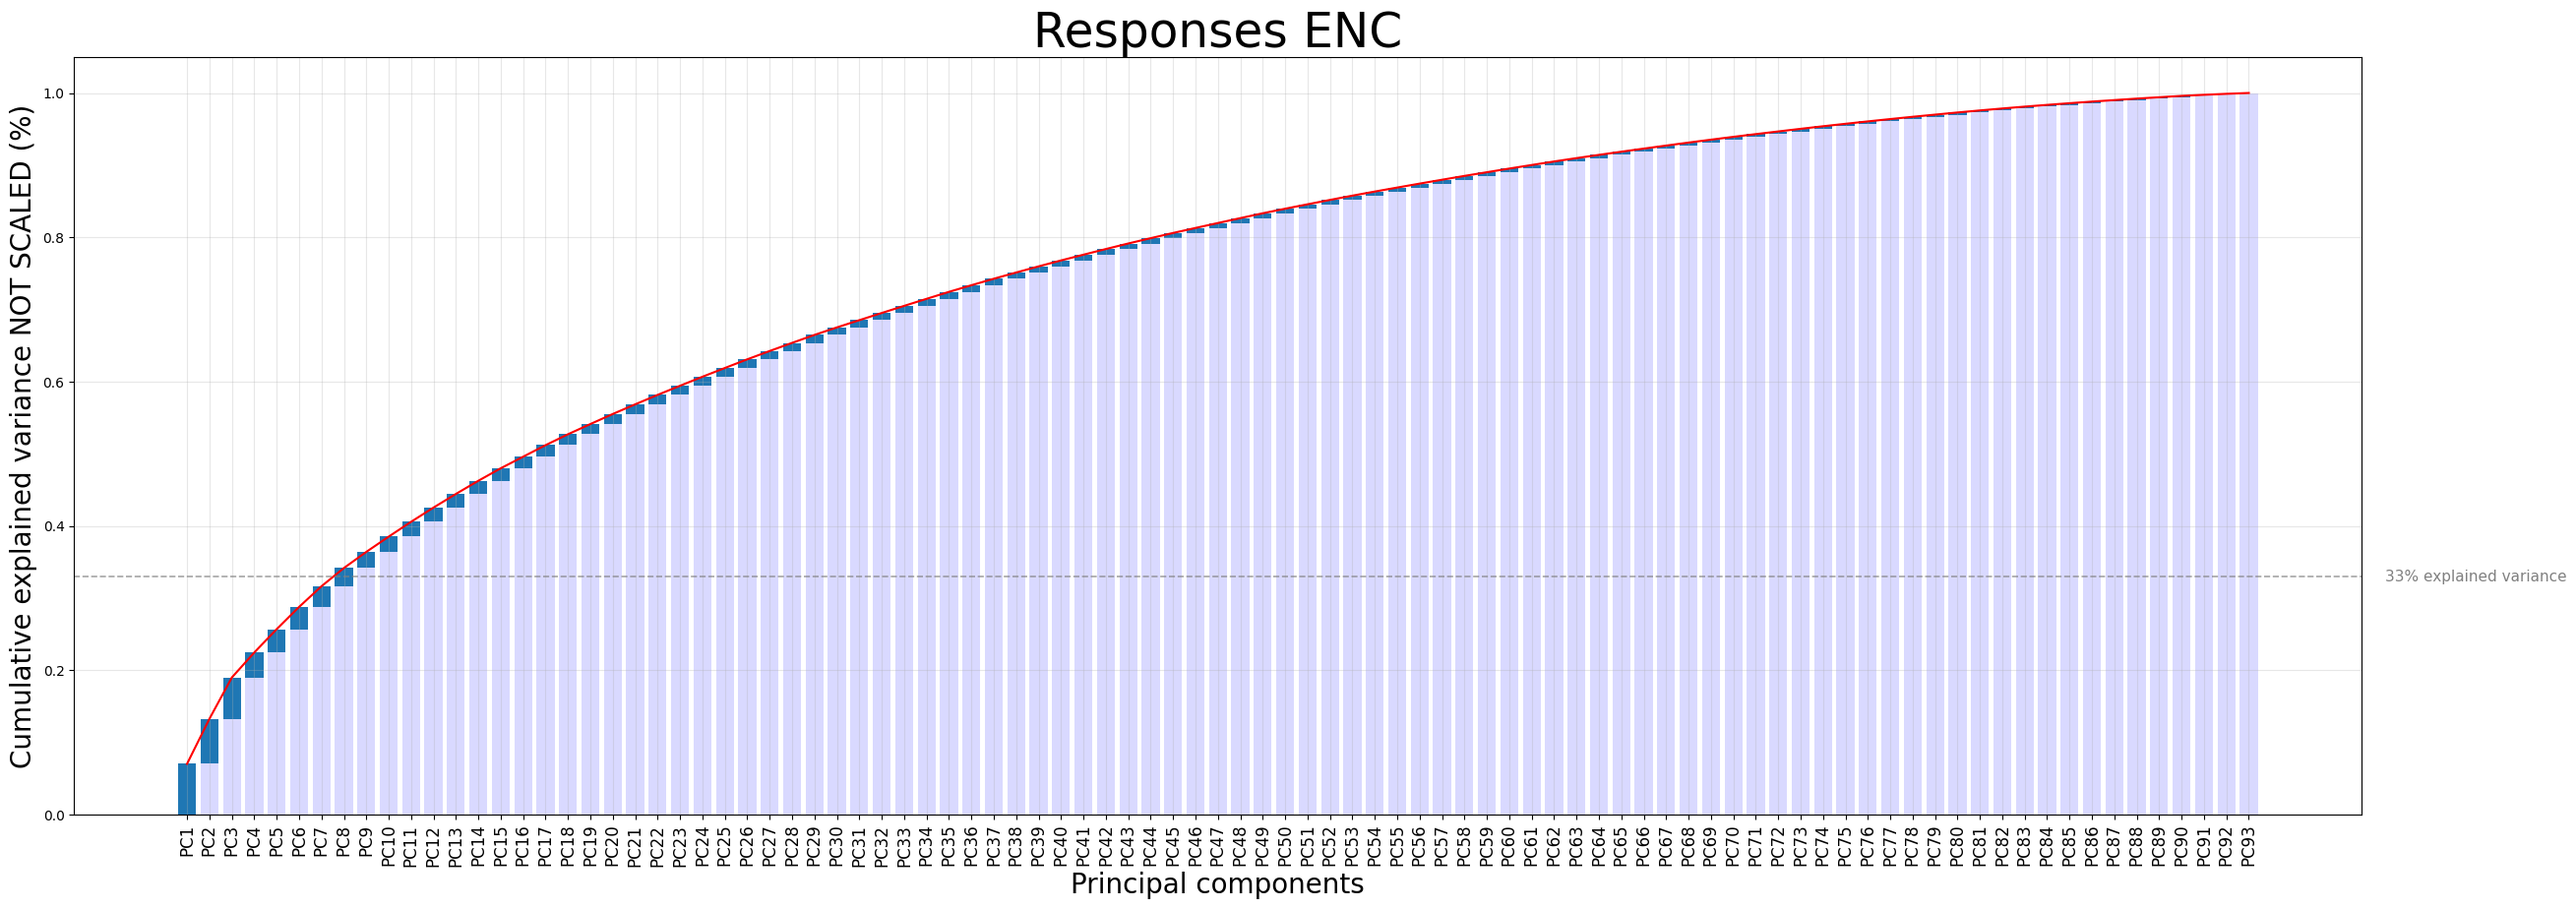

In [7]:
pca_enc = PCA()
pca_enc.fit(responses_ft_enc)
plt.figure(figsize=(30, 10))
plt.bar(np.arange(pca_enc.n_features_in_), pca_enc.explained_variance_ratio_, bottom=np.insert(np.cumsum(pca_enc.explained_variance_ratio_), 0, 0)[:-1])
plt.bar(np.arange(pca_enc.n_features_in_), np.insert(np.cumsum(pca_enc.explained_variance_ratio_), 0, 0)[:-1], color='b', alpha=0.15)
plt.plot(np.cumsum(pca_enc.explained_variance_ratio_), 'r')
plt.axhline(y=0.33, linestyle='--',linewidth=1.2,alpha=0.7,color='gray')
plt.text(
    1.01, 0.33,
    '33% explained variance',
    transform=plt.gca().get_yaxis_transform(),
    fontsize=11,
    color='gray',
    va='center'
)

plt.xticks(ticks=np.arange(pca_enc.n_features_in_),
           labels=[f'PC{i}' for i in range(1, pca_enc.n_features_in_ + 1)], rotation=90,ha='center',
    fontsize=12)
plt.title('Responses ENC',fontsize=35)
plt.xlabel('Principal components',fontsize=20)
plt.ylabel('Cumulative explained variance NOT SCALED (%)',fontsize=20)
plt.grid(alpha=0.3)
plt.show()


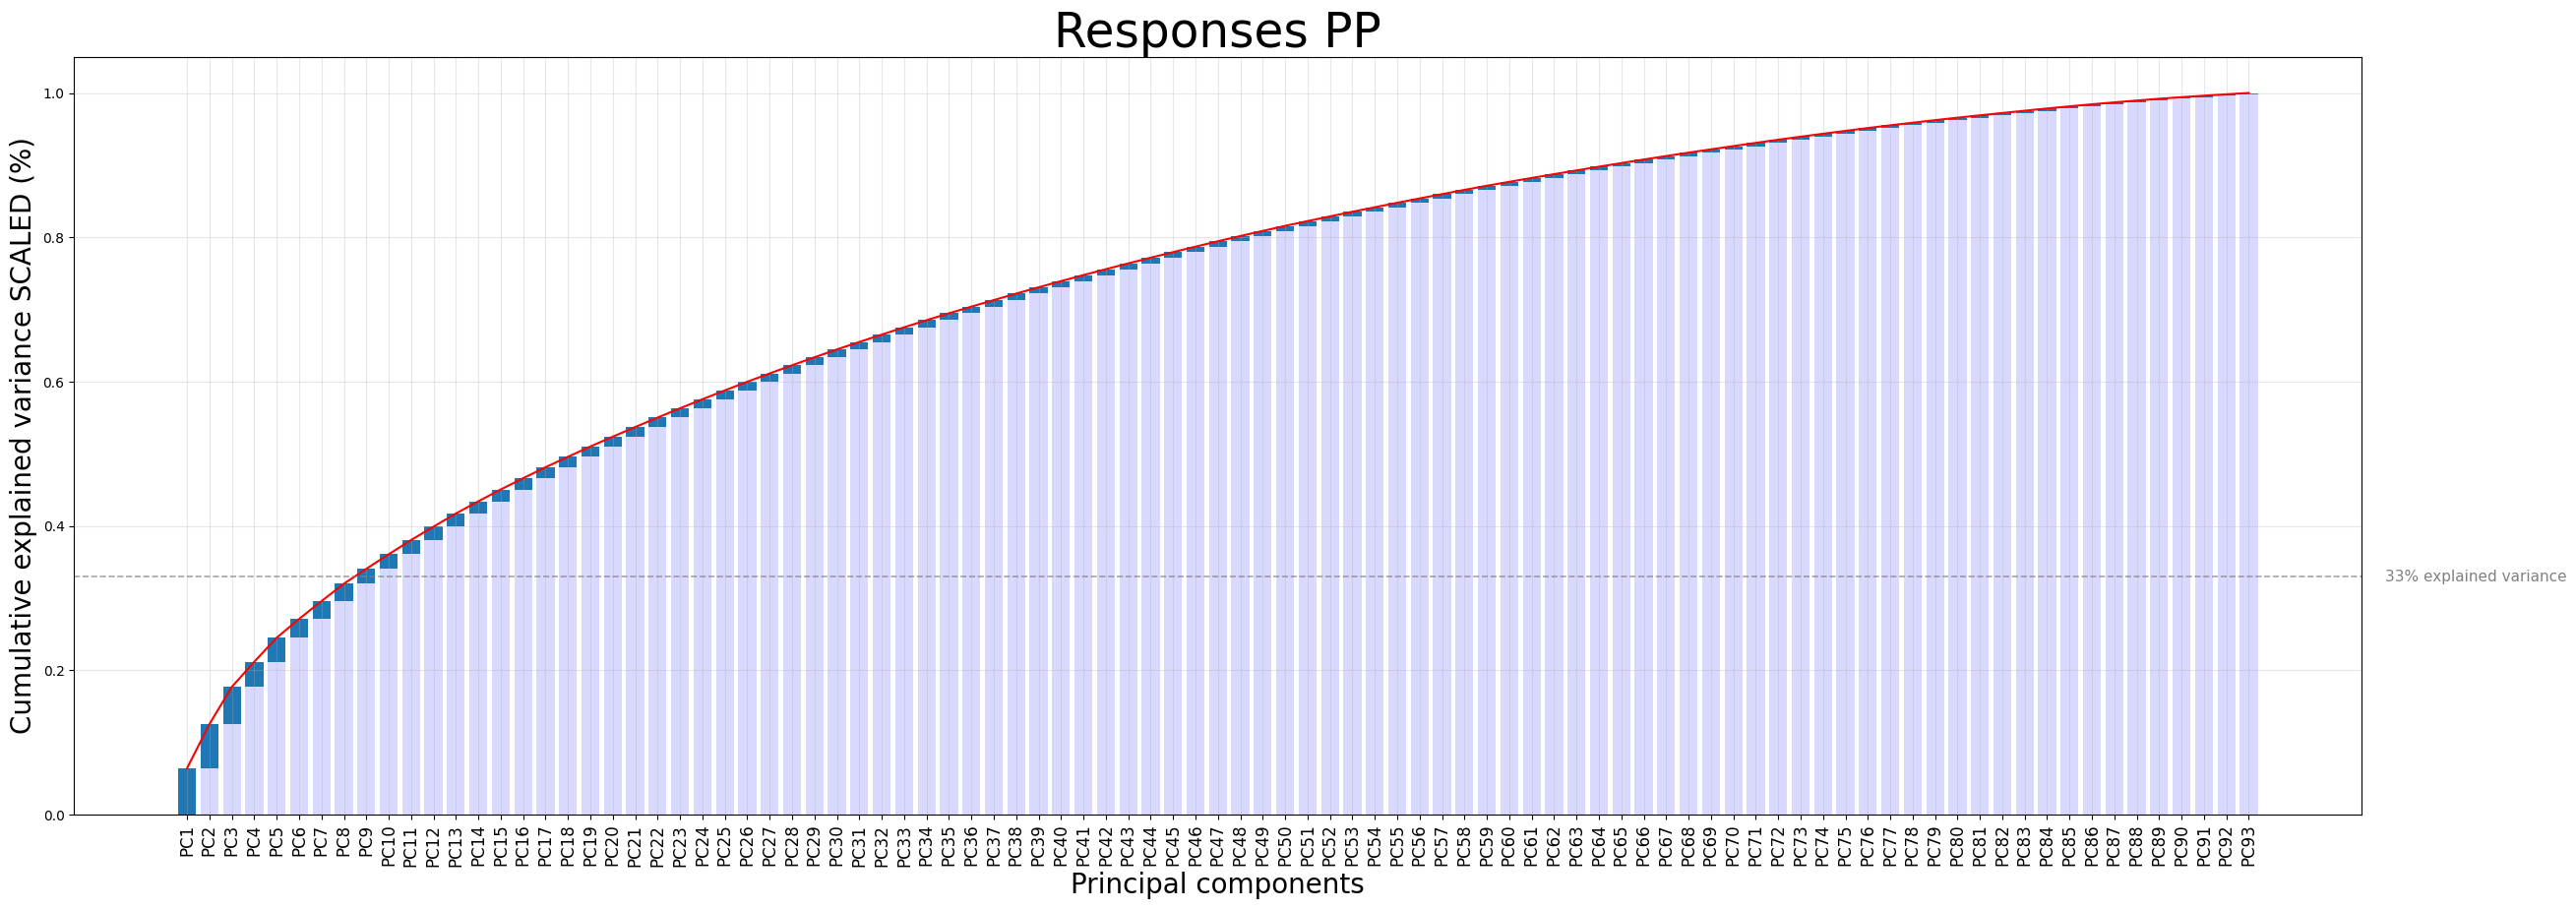

In [8]:
pca_pp = PCA()
pca_pp.fit(responses_ft_pp)
plt.figure(figsize=(30, 10))
plt.bar(np.arange(pca_pp.n_features_in_), pca_pp.explained_variance_ratio_, bottom=np.insert(np.cumsum(pca_pp.explained_variance_ratio_), 0, 0)[:-1])
plt.bar(np.arange(pca_pp.n_features_in_), np.insert(np.cumsum(pca_pp.explained_variance_ratio_), 0, 0)[:-1], color='b', alpha=0.15)
plt.plot(np.cumsum(pca_pp.explained_variance_ratio_), 'r')
plt.axhline(y=0.33, linestyle='--',linewidth=1.2,alpha=0.7,color='gray')
plt.text(
    1.01, 0.33,
    '33% explained variance',
    transform=plt.gca().get_yaxis_transform(),
    fontsize=11,
    color='gray',
    va='center'
)

plt.xticks(ticks=np.arange(pca_pp.n_features_in_),
           labels=[f'PC{i}' for i in range(1, pca_pp.n_features_in_ + 1)],rotation=90,ha='center',fontsize=12)
plt.title('Responses PP',fontsize=35)
plt.xlabel('Principal components',fontsize=20)
plt.ylabel('Cumulative explained variance SCALED (%)',fontsize=20)
plt.grid(alpha=0.3)
plt.show()

#### Comment the results obtained for the cumulative explained variances, knowing the vaues in the datasets and the fetures' variances (max 150 words):
The **cumulative explained** variance curves for the two datasets (before and after scaling) are **almost identical**. This indicates that **no feature in the original data exhibited a sufficiently large variance to dominate the PCA**. Even prior to scaling, the features contributed in a relatively balanced manner to the total variance; consequently, standardization does not substantially modify the distribution of variance across the principal components.

After scaling, all features have unit variance, but since no variable originally had a markedly larger magnitude, the cumulative explained variance increases at nearly the same rate. As a result, the number of components required to reach a given explained variance threshold remains essentially unchanged.

The fact that a **large number of components is needed to explain most of the variance confirms that the dataset is intrinsically high-dimensional**, with **information spread across many features** rather than **concentrated in a small subset.**






## Exercise 3. Dimensionality Reduction and PC Interpretation

In this exercise, you have to do the following operations:
1. For the dataset *responses_ft_pp*, compute a new PCA for performing a dimensionality reduction with respect to $m$ dimensions. The value of $m$ must be $$m = \min\{m', 5\}\,,$$ where $m'$ is the value required for obtaining $33\%$ of the total variance.
1. Visualize as a barplot the explained variance (as percentage) for each PC, and report the preserved explained variance (as percentage) by the $m$ PCs.
1. Visualize all the PCs as barplots and give an interpretation and a name to them, **motivating your choices**.
1. Transform the *responses_ft_pp* data into their $m$-dimensional representation via PCA. Store the transformed data in the variable *responses_ft_pca*;
1. Visualize the the score graph. If $m>3$, plot the score graph with respect to the first 3 PCs. All the **plots must show the names of the PCs (given at the previous step) on the axes** for better understanding the results.

#### Write the code for computing the new PCA, for visualizing the $m$ PCs as barplots:

Minimum number of components explaining at least 33% of the total variance (m'): 9
Final number of retained components (m = min{m', 5}): 5




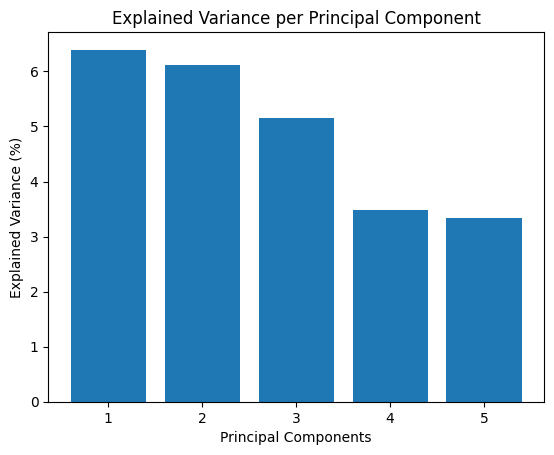

Preserved explained variance with 5 PCs: 24.49%




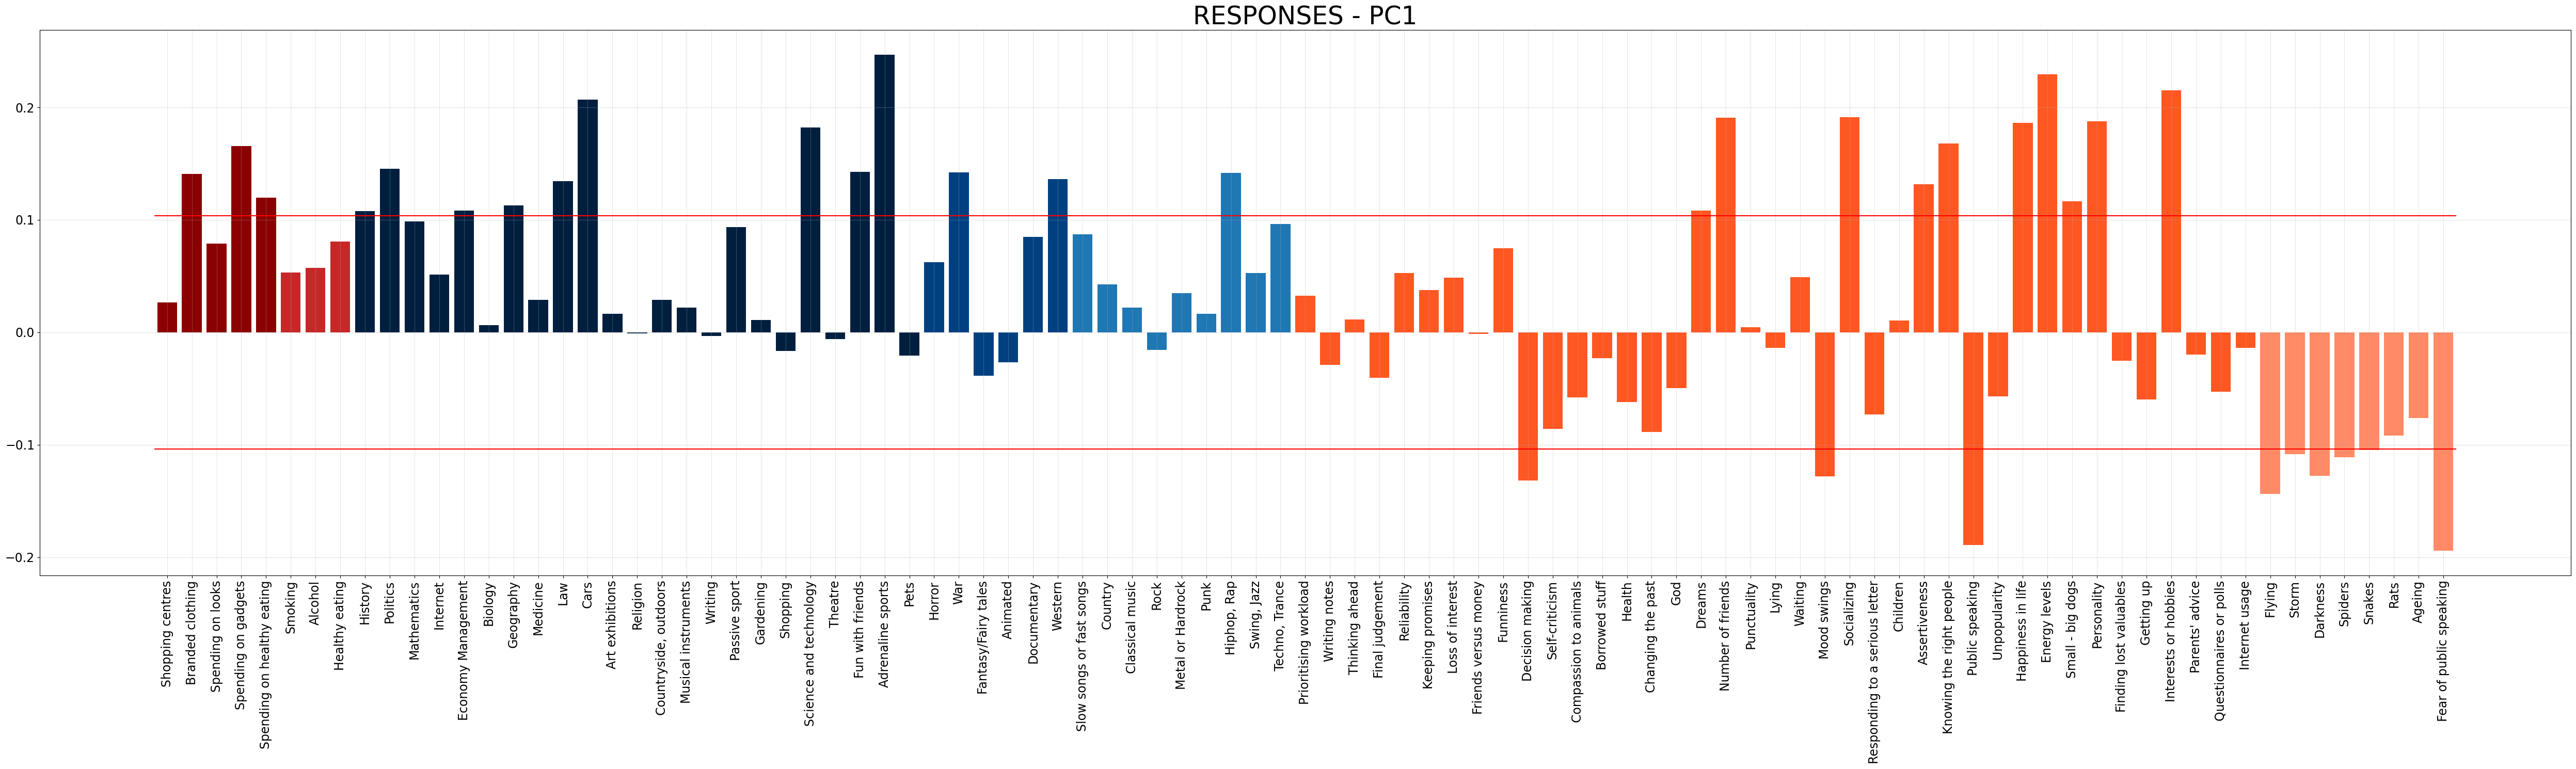

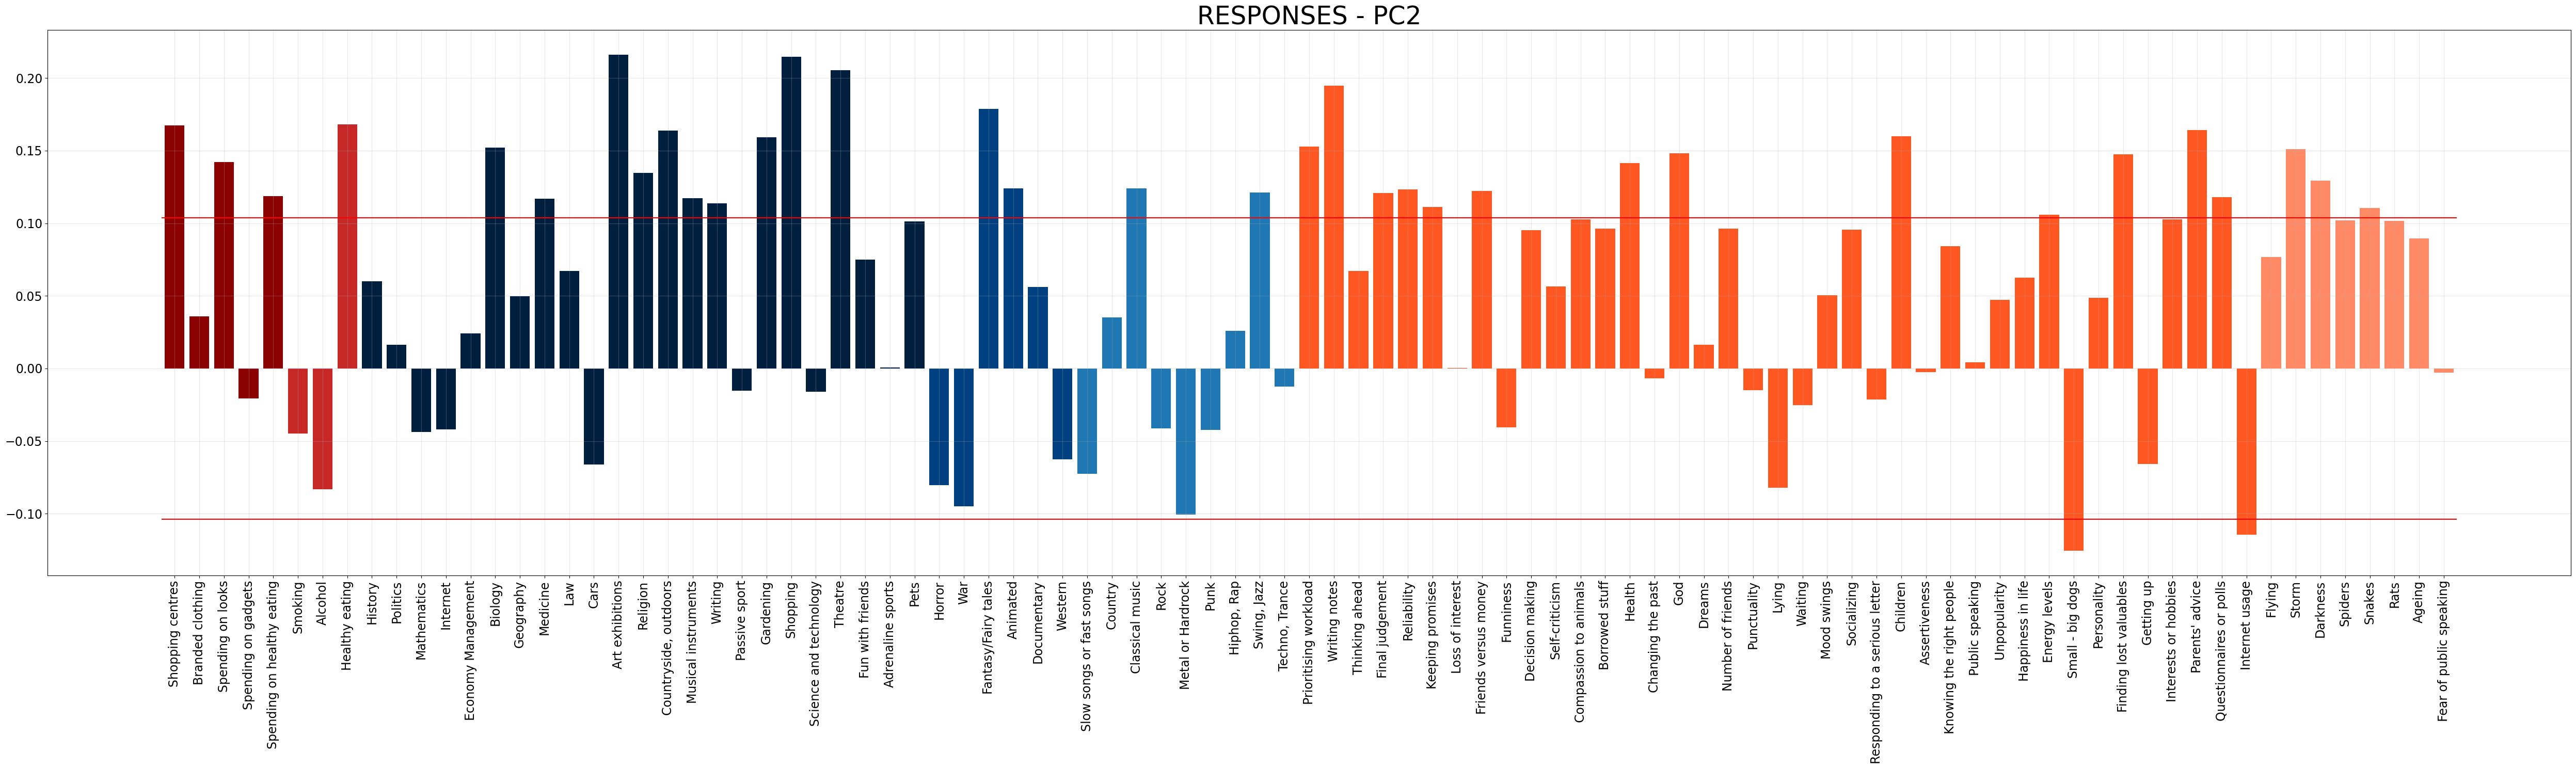

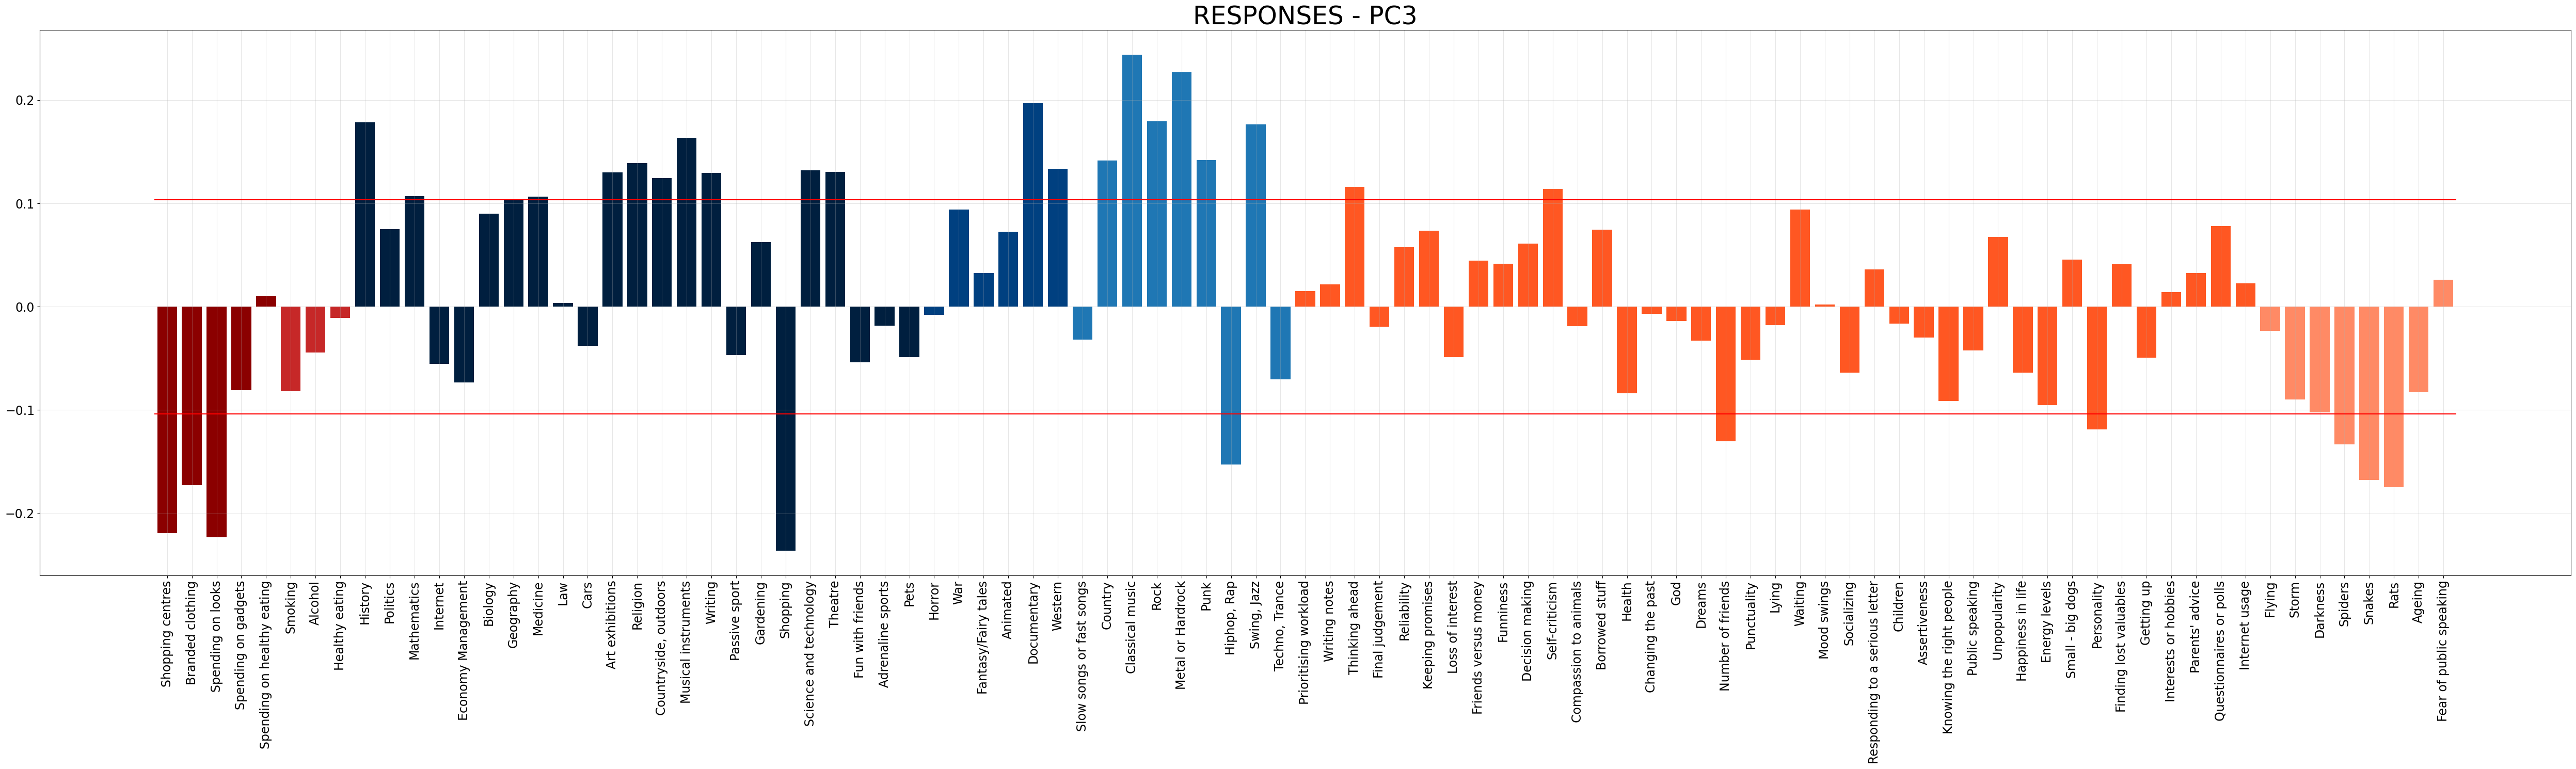

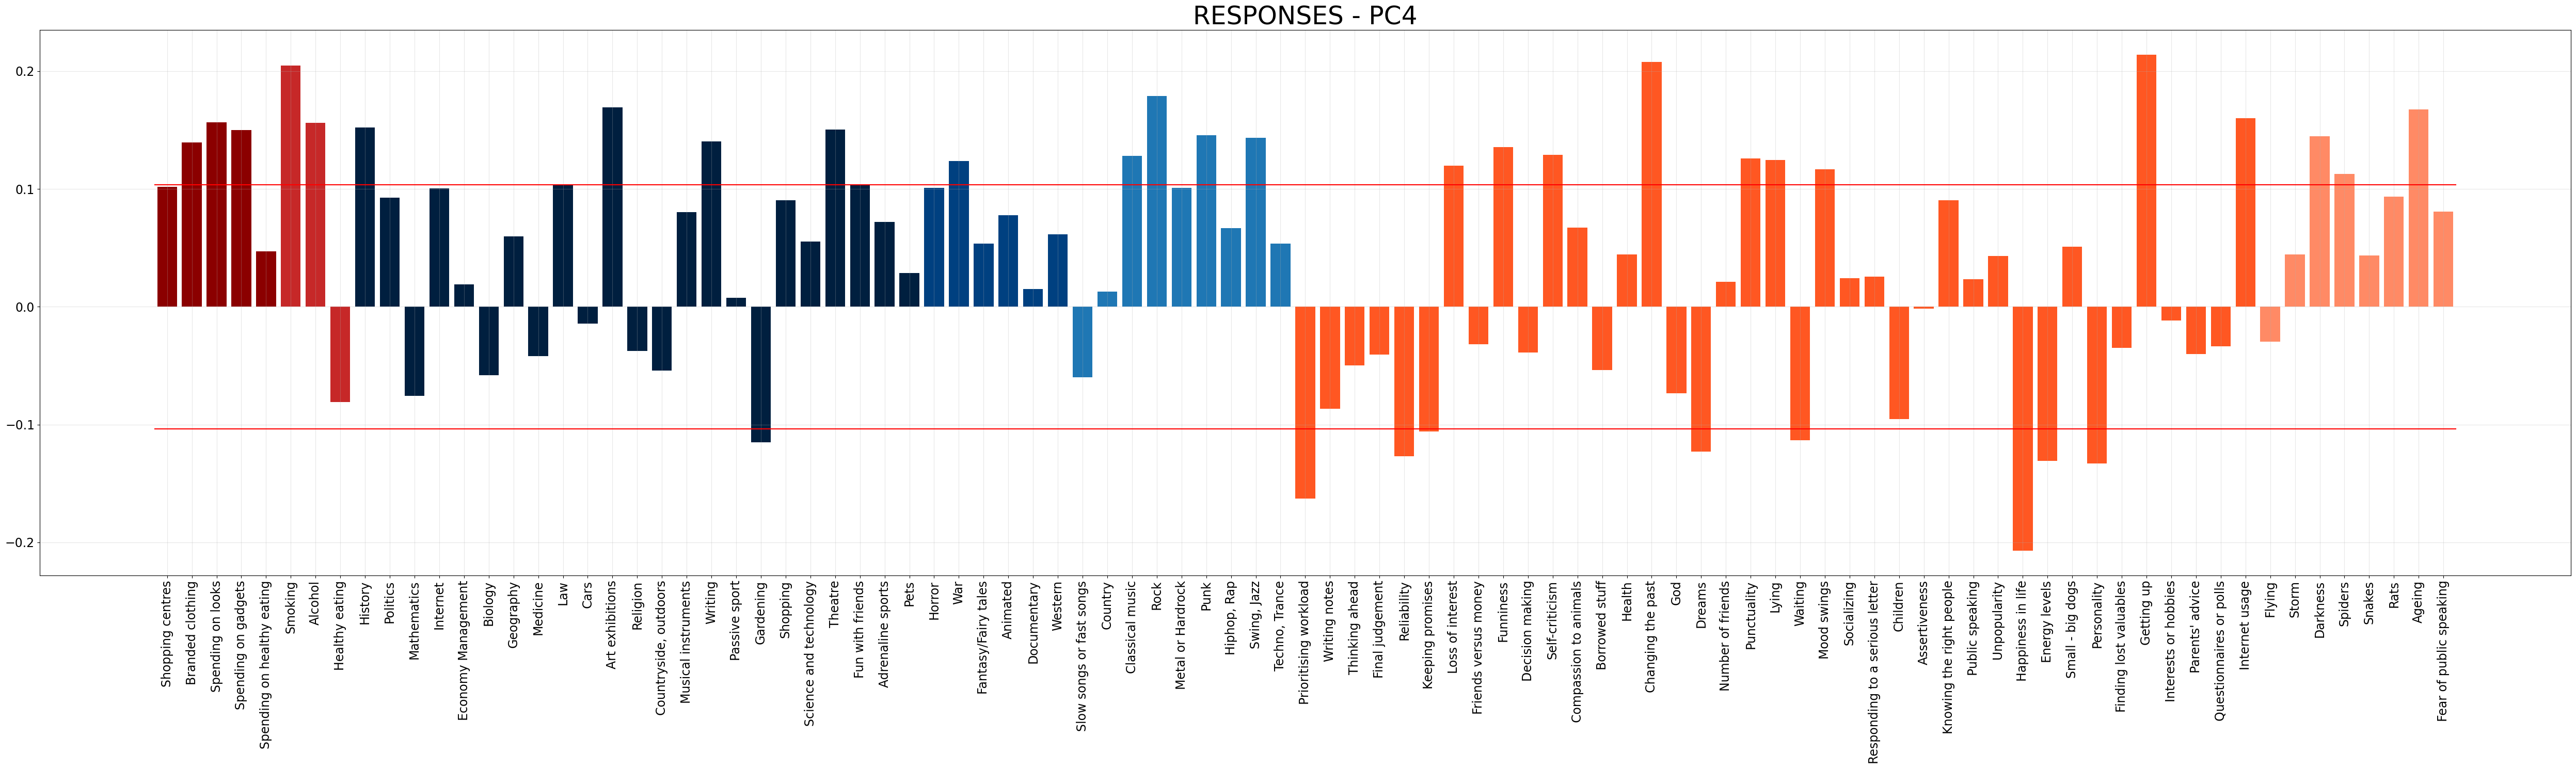

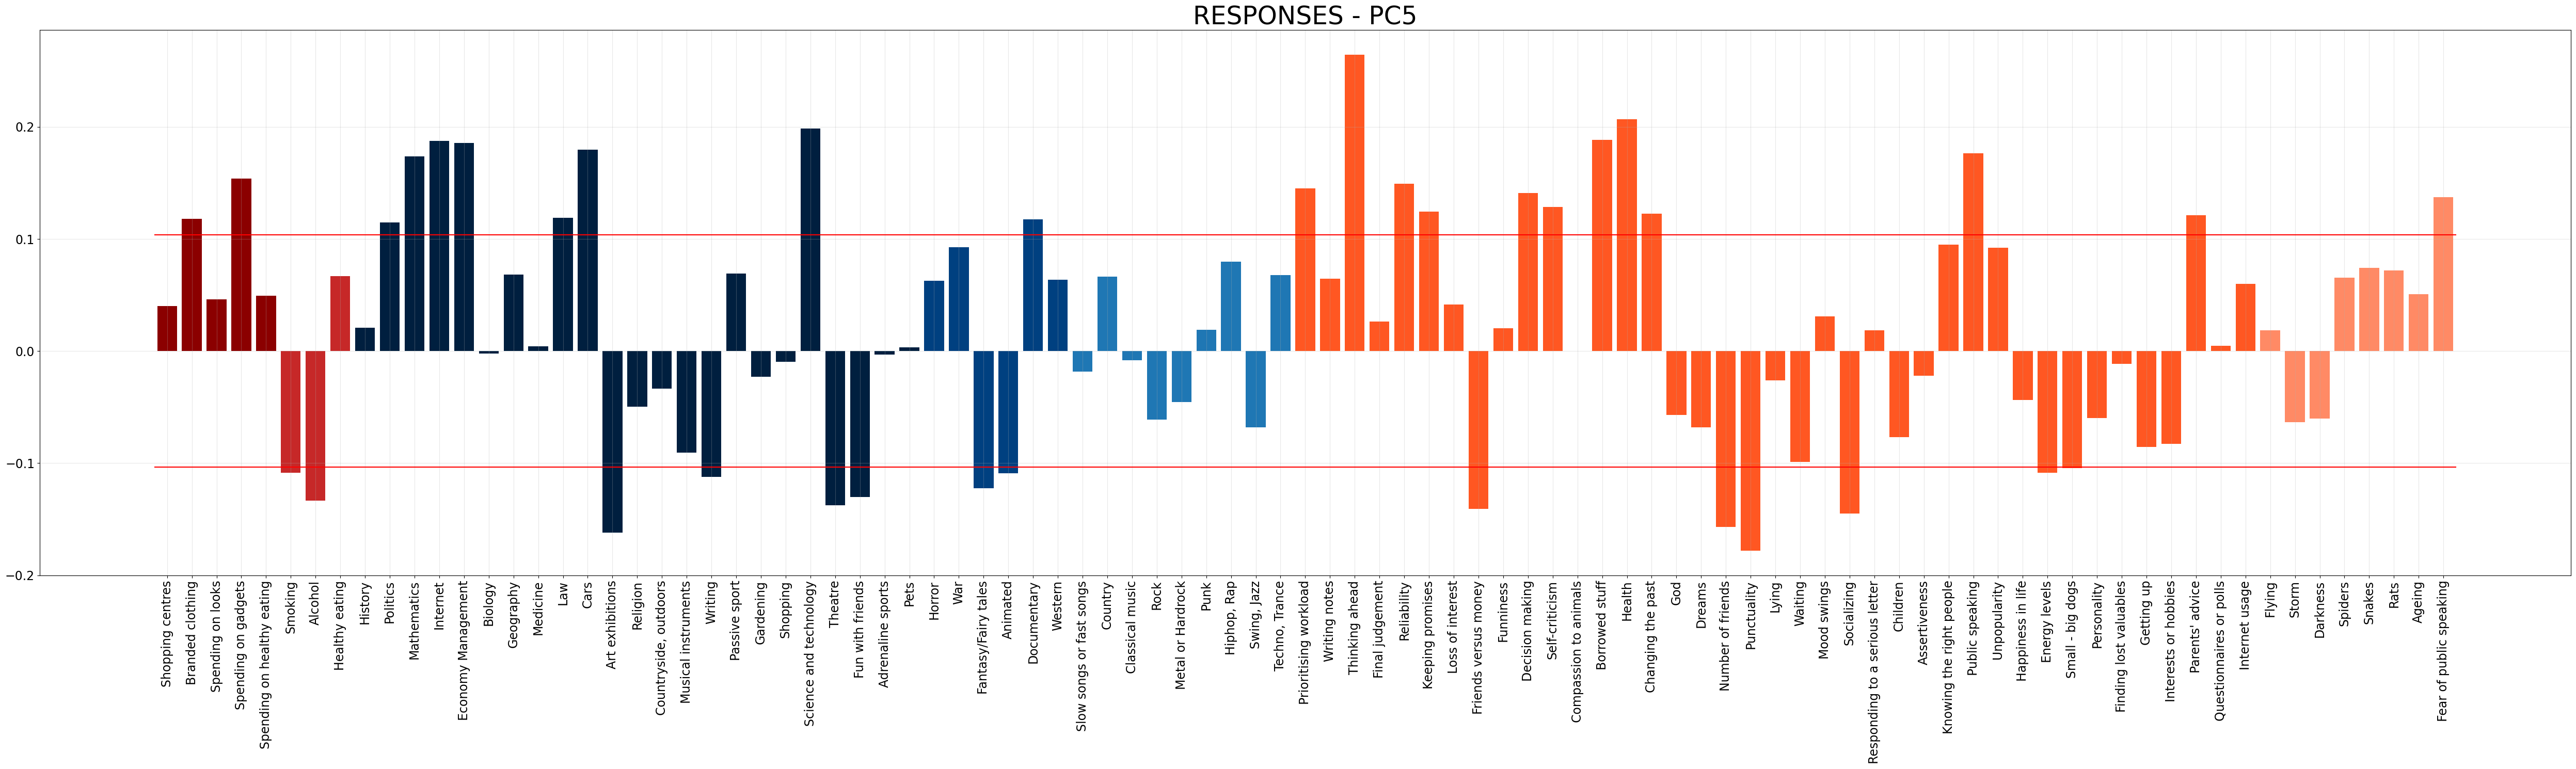

In [9]:
#find m
cumulative_var = np.cumsum(pca_pp.explained_variance_ratio_)
# m' = minimum number of components explaining at least 33% variance
m_prime = np.searchsorted(cumulative_var, 0.33) + 1
# final m
m = min(m_prime, 5)

print("=============================================================")
print(
    f"Minimum number of components explaining at least 33% of the total variance (m'): {m_prime}\n"
    f"Final number of retained components (m = min{{m', 5}}): {m}"
)
print("==============================================================")
print("\n")

#PCA with m components
pca = PCA(n_components=m)
pca.fit(responses_ft_pp)
eps = np.sqrt(1 / pca.n_features_in_)


#plot 1
explained_var = pca.explained_variance_ratio_ * 100
plt.bar(range(1, len(explained_var)+1), explained_var)
plt.xlabel("Principal Components")
plt.ylabel("Explained Variance (%)")
plt.title("Explained Variance per Principal Component")
plt.show()
# preserved variance by first m PCs
preserved = explained_var[:m].sum()
print("==============================================================")
print(f"Preserved explained variance with {m} PCs: {preserved:.2f}%")
print("==============================================================")
print("\n")


#plots for PC components
plt.figure(figsize=(50, 15))
plt.bar(np.arange(pca.n_features_in_), pca.components_[0, :], color=colors_pp)
plt.plot([-0.5, pca.n_features_in_ - 0.5], [eps, eps], 'red')
plt.plot([-0.5, pca.n_features_in_ - 0.5], [-eps, -eps], 'red')
plt.xticks(ticks=np.arange(pca.n_features_in_),
           labels=responses_ft_pp.columns.to_list(),
           rotation=90,fontsize=17)
plt.yticks(fontsize=17)
plt.title('RESPONSES - PC1',fontsize=35)
plt.tight_layout()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(50, 15))
plt.bar(np.arange(pca.n_features_in_), pca.components_[1, :], color=colors_pp)
plt.plot([-0.5, pca.n_features_in_ - 0.5], [eps, eps], 'red')
plt.plot([-0.5, pca.n_features_in_ - 0.5], [-eps, -eps], 'red')
plt.xticks(ticks=np.arange(pca.n_features_in_),
           labels=responses_ft_pp.columns.to_list(),
           rotation=90,fontsize=17)
plt.yticks(fontsize=17)
plt.title('RESPONSES - PC2', fontsize=35)
plt.tight_layout()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(50, 15))
plt.bar(np.arange(pca.n_features_in_), pca.components_[2, :], color=colors_pp)
plt.plot([-0.5, pca.n_features_in_ - 0.5], [eps, eps], 'red')
plt.plot([-0.5, pca.n_features_in_ - 0.5], [-eps, -eps], 'red')
plt.xticks(ticks=np.arange(pca.n_features_in_),
           labels=responses_ft_pp.columns.to_list(),
           rotation=90,fontsize=17)
plt.yticks(fontsize=17)
plt.title('RESPONSES - PC3', fontsize=35)
plt.tight_layout()
plt.grid(alpha=0.3)
plt.show()


plt.figure(figsize=(50, 15))
plt.bar(np.arange(pca.n_features_in_), pca.components_[3, :], color=colors_pp)
plt.plot([-0.5, pca.n_features_in_ - 0.5], [eps, eps], 'red')
plt.plot([-0.5, pca.n_features_in_ - 0.5], [-eps, -eps], 'red')
plt.xticks(ticks=np.arange(pca.n_features_in_),
           labels=responses_ft_pp.columns.to_list(),
           rotation=90,fontsize=17)
plt.yticks(fontsize=17)
plt.title('RESPONSES - PC4', fontsize=35)
plt.tight_layout()
plt.grid(alpha=0.3)
plt.show()


plt.figure(figsize=(50, 15))
plt.bar(np.arange(pca.n_features_in_), pca.components_[4, :], color=colors_pp)
plt.plot([-0.5, pca.n_features_in_ - 0.5], [eps, eps], 'red')
plt.plot([-0.5, pca.n_features_in_ - 0.5], [-eps, -eps], 'red')
plt.xticks(ticks=np.arange(pca.n_features_in_),
           labels=responses_ft_pp.columns.to_list(),
           rotation=90,fontsize=17)
plt.yticks(fontsize=17)
plt.title('RESPONSES - PC5', fontsize=35)
plt.tight_layout()
plt.grid(alpha=0.3)
plt.show()




#### For each PC, write the name you assigned to it and a brief interpretation that motivate the choice (max 100 words per PC):

**PC1 = Extraversion & Social Energy (+) vs Anxiety & Emotional Sensitivity (-)** This component separates energetic and socially active individuals, who score highly on *fun with friends*, *adrenaline sports* and *spending on looks*, from more introverted and anxious individuals. The negative side shows stronger fears such as *flying, spiders* and *public speaking*, a marked need to *prepare before talking in public*, greater difficulty in *making decisions* and more frequent *mood swings*. Overall, PC1 contrasts a socially energetic, stimulation-seeking profile with individuals characterised by emotional sensitivity, caution and anxiety.

**PC2 = Responsibility & Cultural interests (+) vs High Online Activity & Strength-focused tendencies (-)** This component contrasts conscientious and caring individuals, who score highly on *healthy eating*, *prioritising workload*, *making lists to stay organised*, enjoying the company of *children* and listening to their *parents’ advice*. Most importantly, they show strong interest in *art*, *shopping*, *theatre*, *outdoor activities* and *religion*. On the opposite side are individuals characterised by very high *internet usage* and a clear preference for *big and dangerous dogs*. Relevant interests include *hard rock and metal music*, as well as *war and horror movies*, which collectively reflect strength-focused tendencies. PC2 therefore separates structured responsibility from more dominant and digitally absorbed profiles.

**PC3 = Cultural–Music Appreciation (+) vs Materialistic Interests(-)** This component contrasts individuals with strong cultural and melodic preferences, who score highly on *classical music*, *jazz*, *documentaries*, *hisotry*,  *art exhibitions*  or *theatre* interests, with individuals displaying a more materialistic and urban lifestyle. The negative side shows higher scores on *shopping centres*, *branded clothing*, *spending* on gadgets and preferences for *hip hop* and *rap* music. Overall, PC3 separates reflective and culture oriented tastes from consumption driven and urban expressive tendencies.

**PC4 = Vices, Regret & Intense Cultural Interests (+) vs Stable & Satisfied Personality(-)** This component contrasts individuals marked by vices and emotional turbulence, who show higher scores in *smoking*, *alcohol* use, intense artistic interests such as *art exhibitions* and  *writing*, preferences for *rock* and *jazz* music, regretful attitudes such as wanting to *change the past*, *mood swings*, *loss of interest* in love, *difficulty in getting up*, high internet usage, with individuals who report stability and satisfaction. The negative side includes higher *reliability*, *prioritising workload*, *gardening*, *happiness in life*, high *energy levels* and a *positive view of their personality*.

**PC5 = Analytical, Structured Thinking vs Sociable, Expressive & Indulgent Tendencies**  This component contrasts methodical and disciplined individuals, who score highly on *thinking ahead*, *prioritising workload* and *reliability*, together with stronger interests in *mathematics*, *economy* and *science and technology*, with socially expressive people who enjoy *friendships*, *socialising* *animated* and *fantasy* films, *art exhibitions* as well as vices such as *smoking* and *alcohol* use. PC5 therefore separates analytical and reliable individuals from more sociable and indulgent profiles.



#### Write the code for visualizing the score graph (with PC names on the axis):

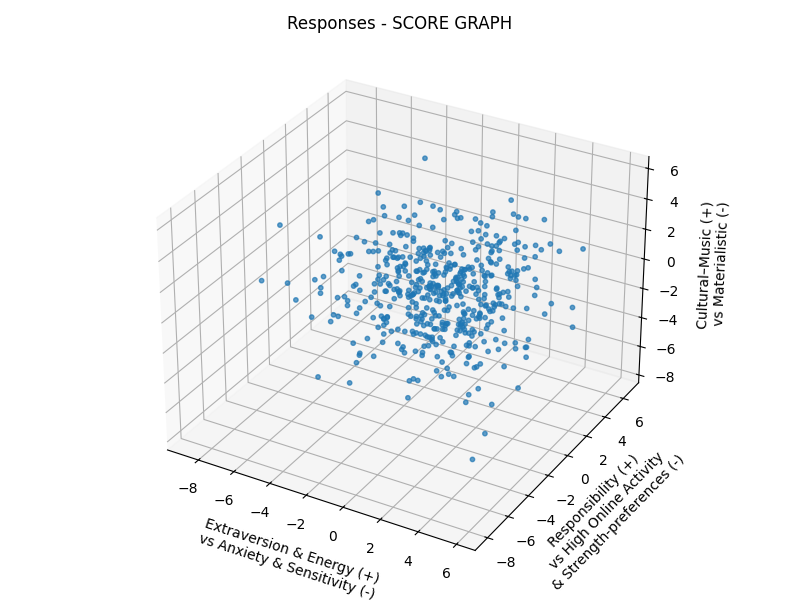

In [10]:
%matplotlib widget
Y=pca.transform(responses_ft_pp)

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(Y[:, 0], Y[:, 1], Y[:, 2], alpha=0.7, s=10)
plt.title("Responses - SCORE GRAPH")

ax.set_xlabel("Extraversion & Energy (+)\nvs Anxiety & Sensitivity (-)", labelpad=10)
ax.set_ylabel("Responsibility (+) \nvs High Online Activity\n& Strength-preferences (-)",  labelpad=10)
ax.set_zlabel("Cultural–Music (+) \nvs Materialistic (-)",  labelpad=10) #questo su colab non lo fa vedere perchè fa schifo, ma su python va
plt.grid(True, linestyle="--", linewidth=0.5, alpha=0.3)
plt.tight_layout()
plt.show()

## Exercise 4. $k$-Means

In this exercise, you have to do the following operations:
1. Run the $k$-Means for clustering the data of *responses_ft_pca*, **setting the input argument *random_state* equal to the variable *random_seed*** (i.e., the minimum of the Student IDs).

   In particular, **use the silohuette score for identifying the best value for $k\in\{3, \ldots, 10\}$** and show it by plotting how the score changes w.r.t. $k$.
1. Plot the score graph again, but add the centroids of the cluster and color the points according to their cluster.
1. Visualize the centroids coordinates as barplots and **give a name and an interpretation to them by exploiting the PC names**.


#### Write the code for performing the items of the list above:

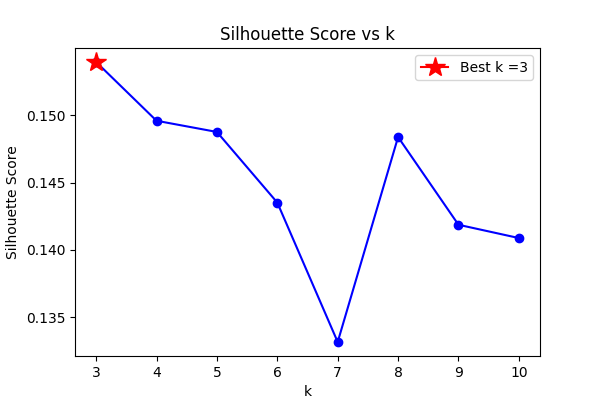


Best k =3, Silhouette Score= 0.15394399950417786



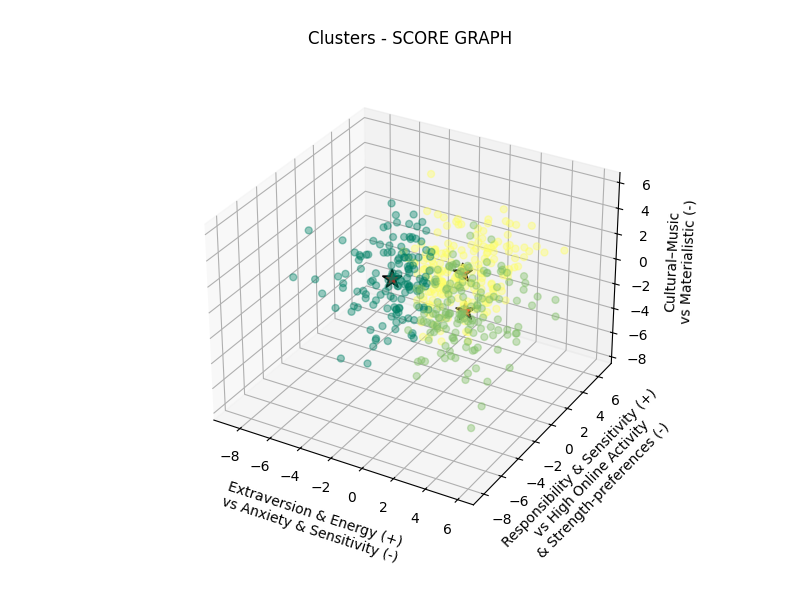

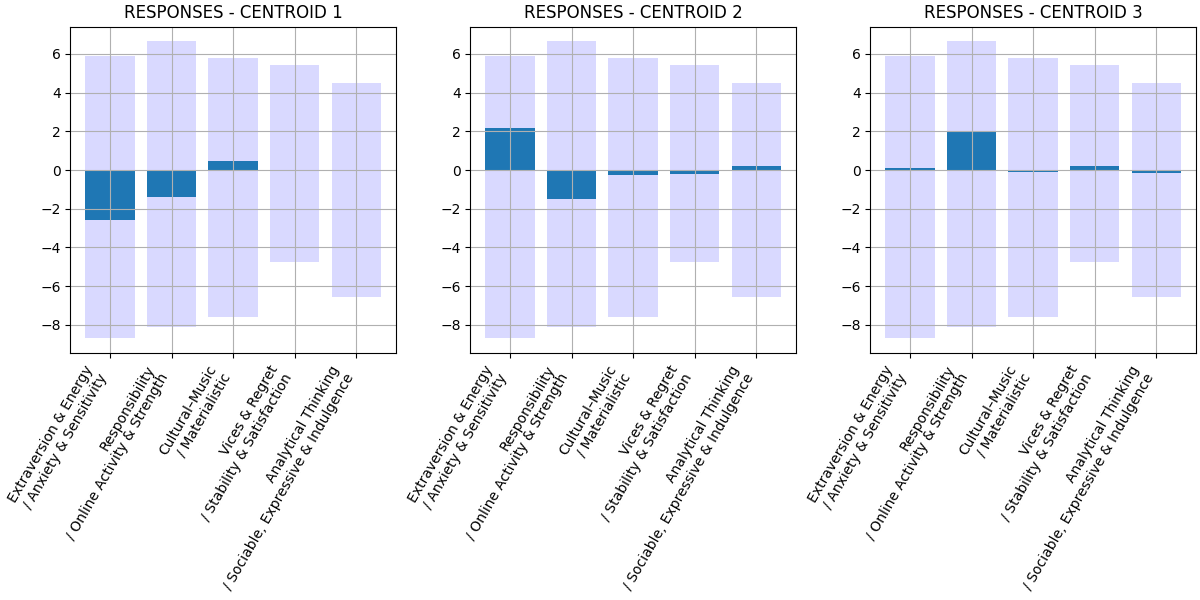

In [12]:
#find best k:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_scores=[]
for k in range(3,11):
  km_prova=KMeans(n_clusters=k,random_state=random_seed)
  km_prova.fit(Y)
  cluster_labels=km_prova.labels_
  score=silhouette_score(Y,cluster_labels)
  silhouette_scores.append(score)

#plot silhouette scores vs k
fig,ax=plt.subplots(figsize=(6,4))
ax.plot(range(3,11),silhouette_scores,marker='o', linestyle="-", color="blue")
best_k_index=np.argmax(silhouette_scores)
best_k=range(3,11)[best_k_index]
best_score=silhouette_scores[best_k_index]
ax.plot(best_k,best_score,marker="*",markersize=15, color="red", label=f"Best k ={best_k}")
ax.set_title("Silhouette Score vs k")
ax.set_xlabel("k")
ax.set_ylabel("Silhouette Score")
ax.legend()
plt.xticks(range(3,11))
plt.show()

print("")
print(f"Best k ={best_k}, Silhouette Score= {best_score}")
print("")


#now actually implement the kMeans:
km = KMeans(n_clusters=best_k,random_state=random_seed)
clusters = km.fit_predict(Y)

maxs_responses = Y.max(axis=0)
mins_responses = Y.min(axis=0)

respPC1 = "Extraversion & Energy\n / Anxiety & Sensitivity"
respPC2 = "Responsibility\n / Online Activity & Strength"
respPC3 = "Cultural–Music\n / Materialistic"
respPC4 ="Vices & Regret\n / Stability & Satisfaction"
respPC5= "Analytical Thinking\n / Sociable, Expressive & Indulgence"

labels = [respPC1, respPC2, respPC3, respPC4, respPC5]

centroids = km.cluster_centers_ # coordinate dei centroidi

#score graph
cmap = plt.get_cmap("summer", km.n_clusters)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(1,1,1, projection='3d')
ax.scatter(
    Y[:, 0], Y[:, 1], Y[:, 2],
    c=clusters, cmap=cmap, s=25, alpha=0.4)

ax.scatter(centroids[:, 0], centroids[:, 1], centroids[:, 2], c='red', marker="*", edgecolor="k", s=200, alpha=1, linewidth=1.2)
ax.set_title("Clusters - SCORE GRAPH", pad=20)

ax.set_xlabel("Extraversion & Energy (+)\nvs Anxiety & Sensitivity (-)", labelpad=10)
ax.set_ylabel("Responsibility & Sensitivity (+)\nvs High Online Activity\n& Strength-preferences (-)", labelpad=10)
ax.set_zlabel("Cultural–Music\nvs Materialistic (-)", labelpad=8)
plt.grid(True, linestyle="--", linewidth=0.5, alpha=0.3)
plt.show()

print("\n")

#bar plots for centroids
fig, ax = plt.subplots(1, 3, figsize=(12, 6), constrained_layout=True)
for ii in range(3):
    ax[ii].bar(np.arange(km.cluster_centers_.shape[1]), maxs_responses, color='blue', alpha=0.15)
    ax[ii].bar(np.arange(km.cluster_centers_.shape[1]), mins_responses, color='blue', alpha=0.15)
    ax[ii].bar(np.arange(km.cluster_centers_.shape[1]), km.cluster_centers_[ii, :])
    ax[ii].set_xticks(np.arange(len(labels)))
    ax[ii].set_xticklabels(labels, rotation=60, ha='right')
    ax[ii].grid(True)
    ax[ii].set_title(f'RESPONSES - CENTROID {ii+1}')
#plt.subplots_adjust(wspace=0.45)
plt.show()


#### For each Centroid, write the name you assigned to it and a brief interpretation that motivate the choice by exploiting the PC names(max 100 words per centroid):

**Centroid 1= The Anxious and Digitally Absorbed**. This centroid is mainly driven by PC1 and PC2, with a minor contribution from PC3, while PC4 and PC5 are negligible. Its strongly negative score on PC1 indicates individuals characterised by anxiety, emotional sensitivity and caution. The negative positioning on PC2 reflects high internet usage and a tendency toward digitally intensive and strength-oriented interests. PC3 suggests a mild inclination toward specific music-related interests, without dominating the overall profile.

**Centroid 2= The Socially Energetic and Internet-Engaged**. The second centroid lies on the positive side of PC1, identifying extroverted, energetic and socially active individuals. Its negative position on PC2 indicates an orientation toward high internet usage and strength-related preferences rather than responsibility- and care-oriented traits. The remaining components contribute marginally, suggesting that this profile is primarily defined by social energy combined with strong digital engagement.

**Centroid 3 = The Responsible and Culturally Oriented**. The third centroid shows a neutral position on most principal components except for a strong positive score on PC2. This indicates individuals characterised by responsibility, structured habits and pronounced cultural and artistic interests. The lack of strong contributions from the other components suggests a focused and well-defined profile, dominated by conscientious attitudes rather than emotional or social extremes.


## Exercise 5. Cluster External Evaluations

In this exercise, you have to do the following operations:
1. Select a subset meaningful labels for performing an external evaluation of the clustering results.
1. For each selected label, visualize the distribution of the label in each cluster and in the whole dataset.
1. Visualize the score graph with dots colored with respect to the label value; then, visualize the clusters in separated score-graphs, coloring the points according to the label values.


#### List the Labels you consider meaningful for an external cluster evaluation and motivate your choice (max 50 words per label):

- **Gender**: gender may capture systematic differences in **social behaviour and emotional expression**, which can influence preferences and lifestyle-related features. This label helps test if the clusters are influenced by gender-related patterns in the survey responses. By evaluating gender distribution across clusters, we can determine if **certain behavioral profiles are more prevalent among specific groups or if the clusters are gender-neutral**.

- **Highest edcation achieved**: **education level is often associated with cultural interests**, responsibility and structured habits.  Using this label helps verify if the clusters are stratified by educational background, revealing whether **specific lifestyle choices or social attitudes** are significantly influenced by an **individual’s academic environment**.

- **Only Child**: **Family structure,** particularly being an only child, **can** significantly **shape personality traits** such as independence and socialization patterns. Including this label allows for an evaluation of whether developmental upbringing and family dynamics correlate with the social engagement and behavioral profiles emerged from the clustering process.


#### Write the code for the visualizations cited in item 2 above:

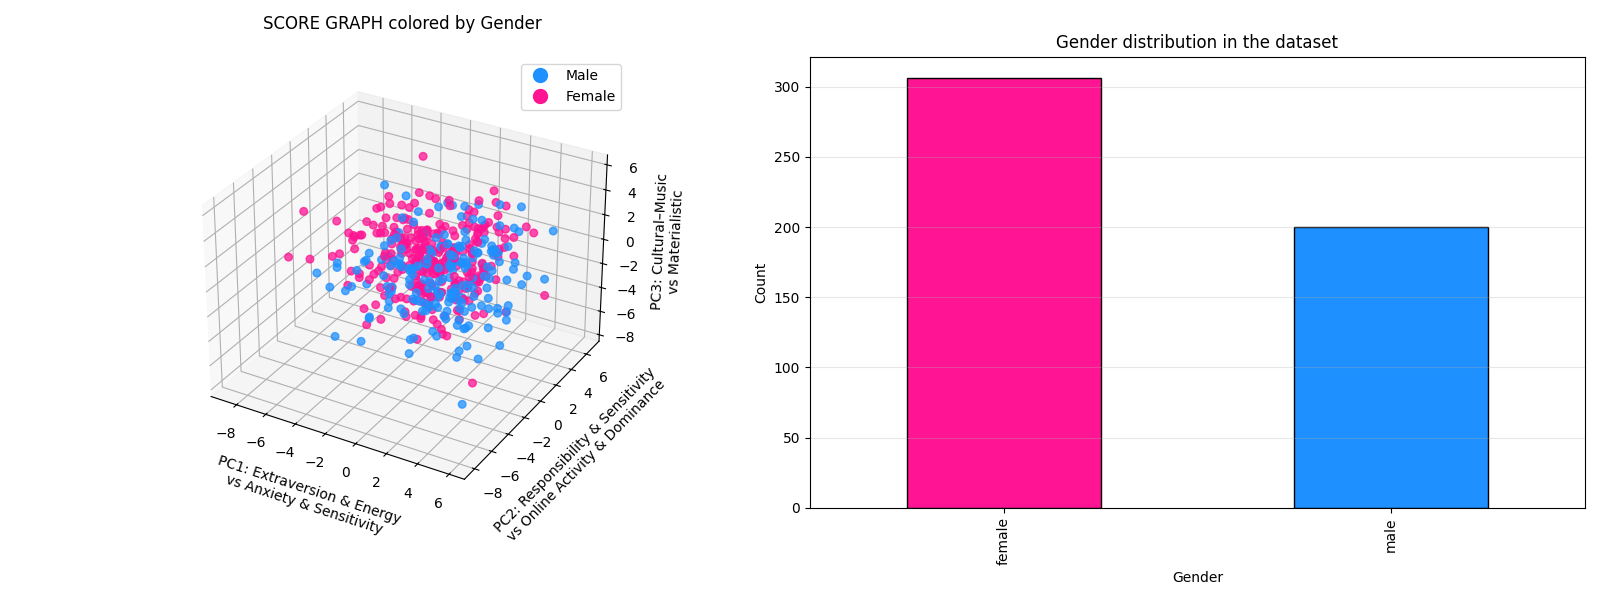

Gender
female    60.474308
male      39.525692
Name: proportion, dtype: float64

--------------------------------------------------



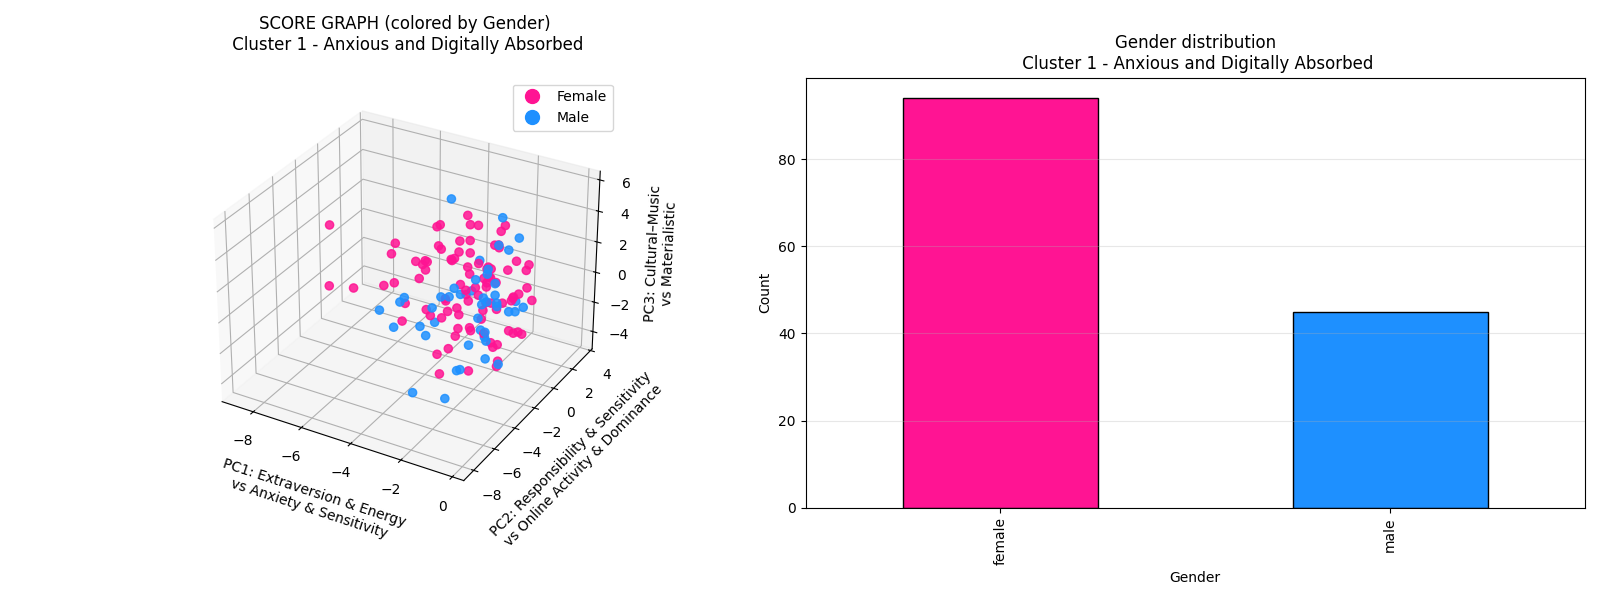


Cluster 1 – Gender percentages:
Gender
female    67.625899
male      32.374101
Name: proportion, dtype: float64

--------------------------------------------------



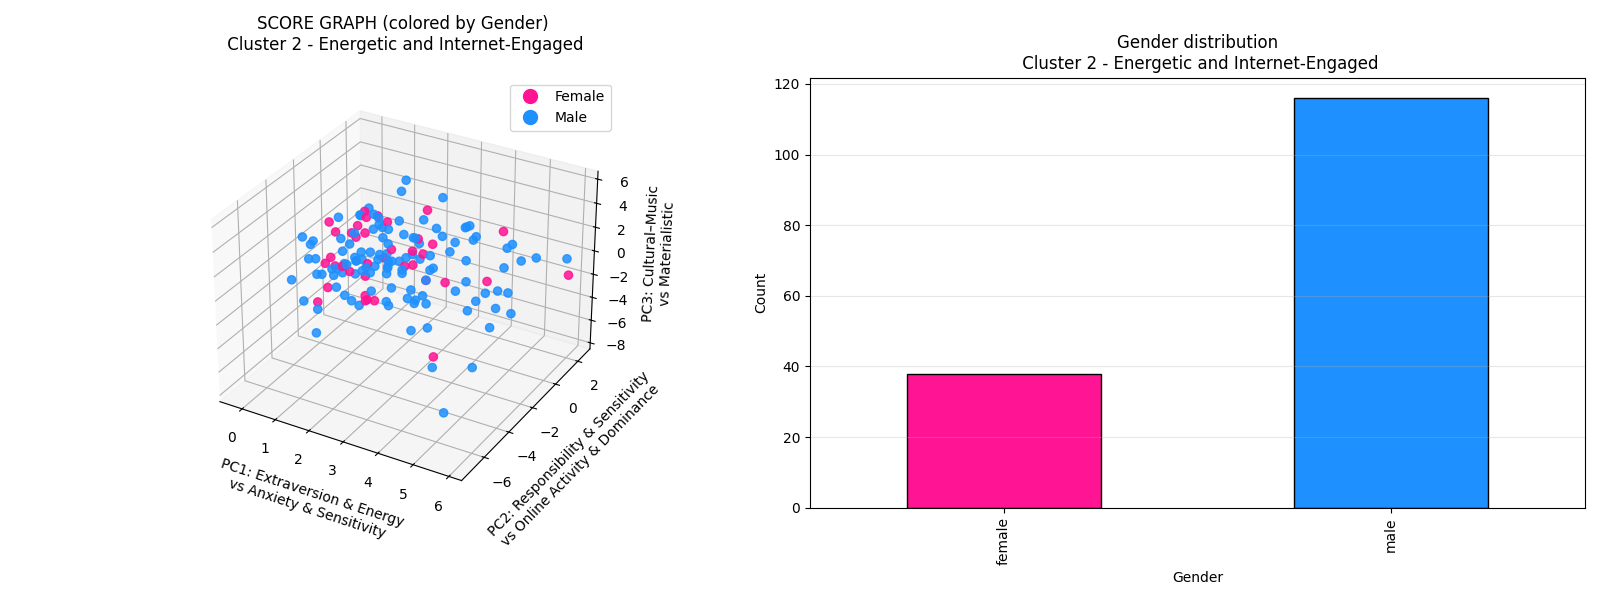


Cluster 2 – Gender percentages:
Gender
female    24.675325
male      75.324675
Name: proportion, dtype: float64

--------------------------------------------------



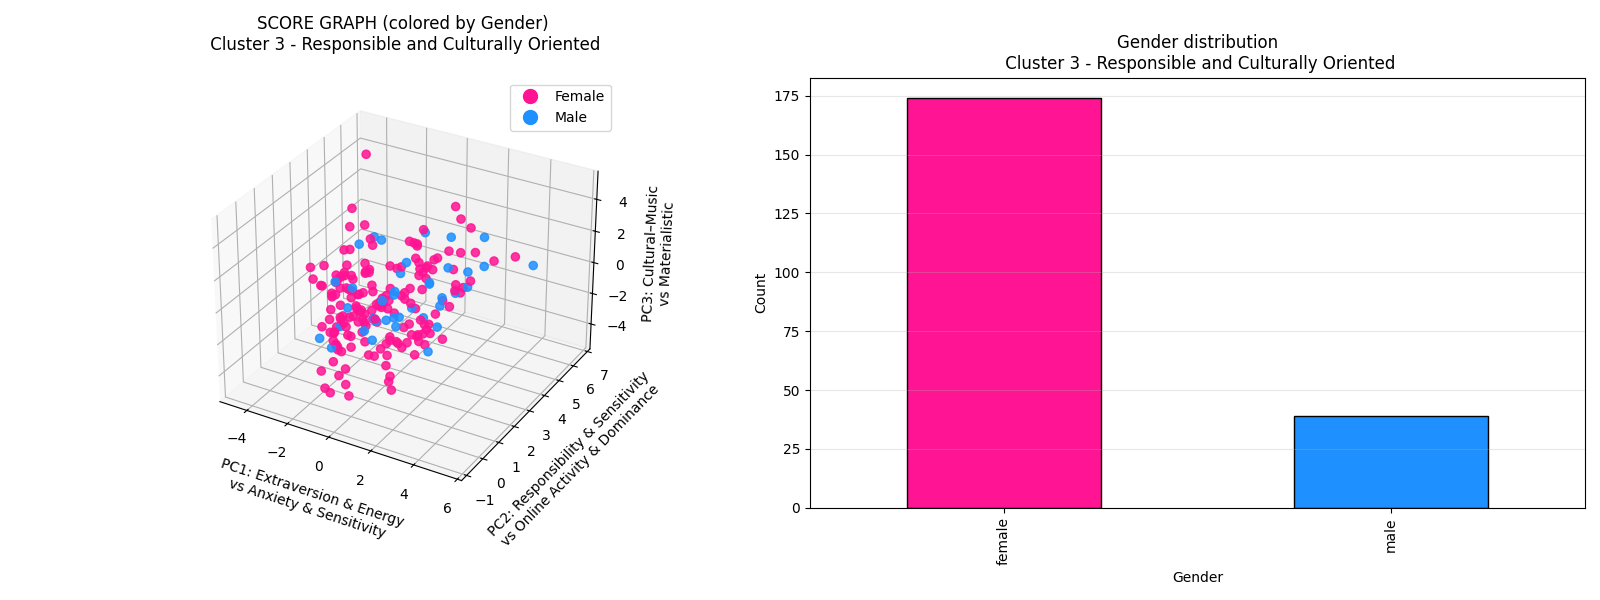


Cluster 3 – Gender percentages:
Gender
female    81.690141
male      18.309859
Name: proportion, dtype: float64

--------------------------------------------------



In [13]:
#DATASET ---------------------------------------------------
gender = responses_lb["Gender"]
gender_colors = gender.map({"male": "dodgerblue", "female": "deeppink"})
fig = plt.figure(figsize=(16, 6))
# --- scoregraph  ---
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.scatter(Y[:, 0], Y[:, 1], Y[:, 2],c=gender_colors,s=30,alpha=0.75)
ax1.set_title("SCORE GRAPH colored by Gender", pad=20)
ax1.set_xlabel("PC1: Extraversion & Energy\nvs Anxiety & Sensitivity", labelpad=10)
ax1.set_ylabel("PC2: Responsibility & Sensitivity\nvs Online Activity & Dominance", labelpad=10)
ax1.set_zlabel("PC3: Cultural–Music\nvs Materialistic", labelpad=8)
labels = {"male": "dodgerblue", "female": "deeppink"}
handles = [ plt.Line2D([], [], marker='o', linestyle='', color=c, label=l.capitalize(), markersize=10) for l, c in labels.items()]
ax1.legend(handles=handles, loc="upper right")

# --- histogram ---
ax2 = fig.add_subplot(1, 2, 2)
responses_lb["Gender"].value_counts().plot(kind="bar",color=["deeppink", "dodgerblue"],edgecolor="black",ax=ax2)
ax2.set_title("Gender distribution in the dataset")
ax2.set_xlabel("Gender")
ax2.set_ylabel("Count")
ax2.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(responses_lb["Gender"].value_counts(normalize=True) * 100)
print("\n" + "-"*50 + "\n")

#CLUSTERS -------------------------------------------------
gender_color_map = {"female": "deeppink", "male": "dodgerblue"}
order_gender = ["female", "male"]
colors_gender = [gender_color_map[g] for g in order_gender]

n_clusters = km.n_clusters
centroid_names=["Anxious and Digitally Absorbed", "Energetic and Internet-Engaged","Responsible and Culturally Oriented"]

for k in range(n_clusters):
    # mask to select individuals of cluster k
    mask_ck = (clusters == k)
    Y_ck = Y[mask_ck]
    gender_ck = responses_lb.loc[mask_ck, "Gender"]
    gender_colors_ck = gender_ck.map(gender_color_map)

    fig = plt.figure(figsize=(16, 6))
    #score graph -----
    ax1 = fig.add_subplot(1, 2, 1, projection='3d')
    ax1.scatter(Y_ck[:, 0], Y_ck[:, 1], Y_ck[:, 2],c=gender_colors_ck, s=35,alpha=0.85)
    ax1.set_title(f"SCORE GRAPH (colored by Gender)\n Cluster {k+1} - {centroid_names[k]}", pad=20)
    ax1.set_xlabel("PC1: Extraversion & Energy\nvs Anxiety & Sensitivity", labelpad=10)
    ax1.set_ylabel("PC2: Responsibility & Sensitivity\nvs Online Activity & Dominance", labelpad=10)
    ax1.set_zlabel("PC3: Cultural–Music\nvs Materialistic", labelpad=8)
    handles = [ plt.Line2D([], [], marker='o', linestyle='', color=gender_color_map[g], label=g.capitalize(), markersize=10) for g in order_gender]
    ax1.legend(handles=handles, loc="upper right")
    #ax1.view_init(elev=22, azim=35)

    # histogram -------
    ax2 = fig.add_subplot(1, 2, 2)
    gender_ck.value_counts().reindex(order_gender).plot( kind="bar",color=colors_gender, edgecolor="black",ax=ax2)
    ax2.set_title(f"Gender distribution\n Cluster {k+1} - {centroid_names[k]}")
    ax2.set_xlabel("Gender")
    ax2.set_ylabel("Count")
    ax2.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

    # stampa percentuali
    print(f"\nCluster {k+1} – Gender percentages:")
    print(gender_ck.value_counts(normalize=True).reindex(order_gender) * 100)
    print("\n" + "-"*50 + "\n")



**Gender**

Evaluating the clusters with respect to the external gender label reveals a clear pattern. **Cluster 2** is predominantly **male**, aligning with the *Socially Energetic and Internet-Engaged* profile. This group reflects traits like high extroversion, energy and strong internet usage, which are more prevalent among male respondents. Conversely, **Cluster 3** is largely **female**, corresponding to the *Responsible and Culturally Oriented* profile, characterized by responsibility and cultural interests more frequently observed in women. **Cluster 1** shows a slight female over-representation (67% vs 60% overall), indicating much **weaker gender-based differentiation**. Overall, these results confirm that gender significantly correlates with the behavioral profiles

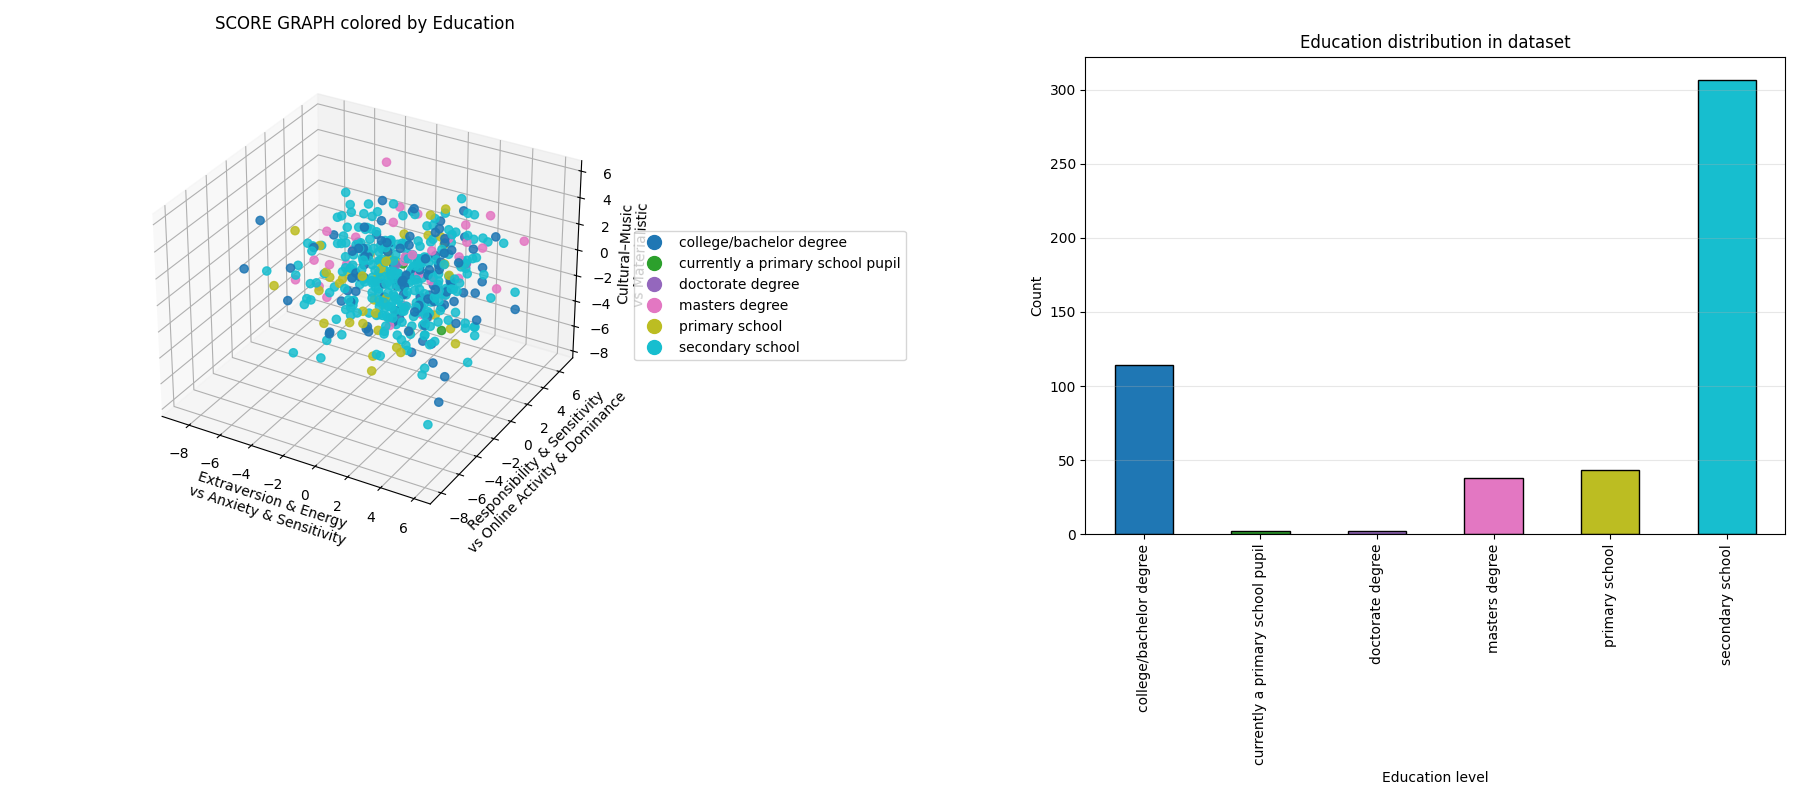

Education
college/bachelor degree             22.529644
currently a primary school pupil     0.395257
doctorate degree                     0.395257
masters degree                       7.509881
primary school                       8.498024
secondary school                    60.671937
Name: proportion, dtype: float64

------------------------------------------------------------



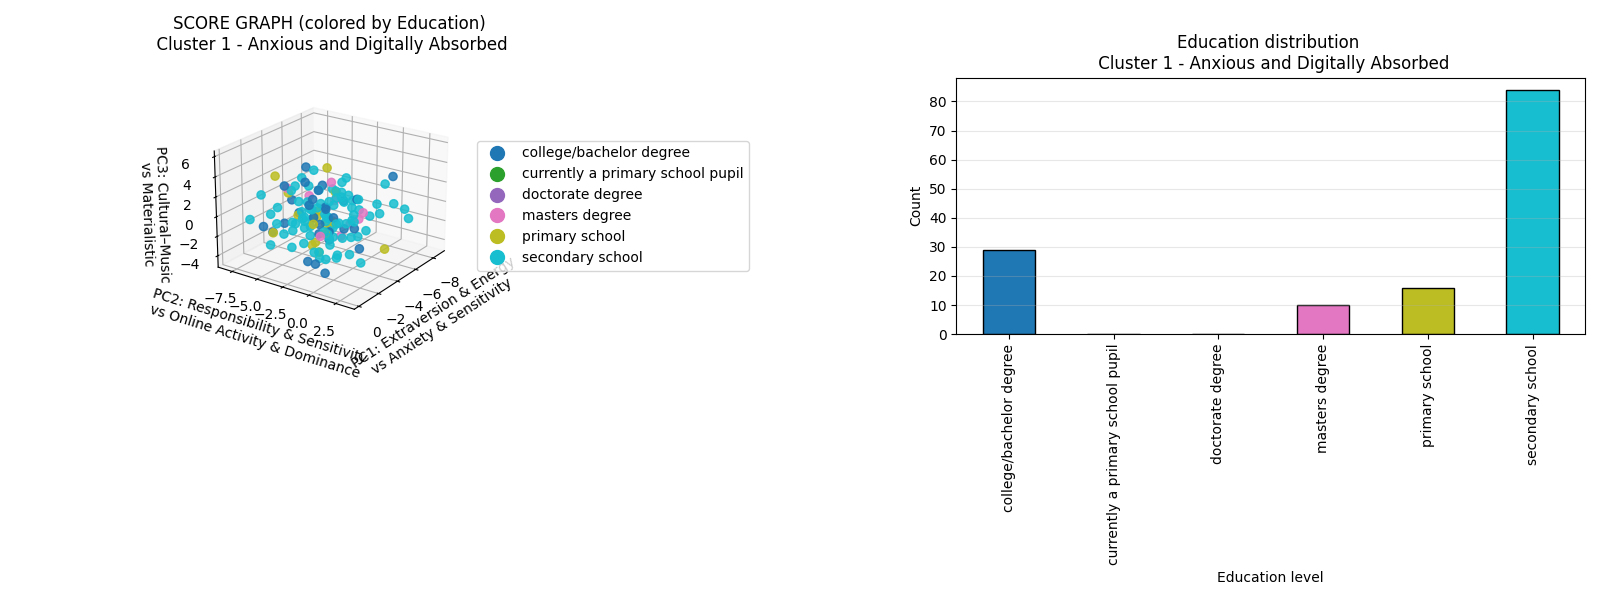


Cluster 1 – Education percentages:
Education
college/bachelor degree             20.863309
currently a primary school pupil          NaN
doctorate degree                          NaN
masters degree                       7.194245
primary school                      11.510791
secondary school                    60.431655
Name: proportion, dtype: float64

------------------------------------------------------------



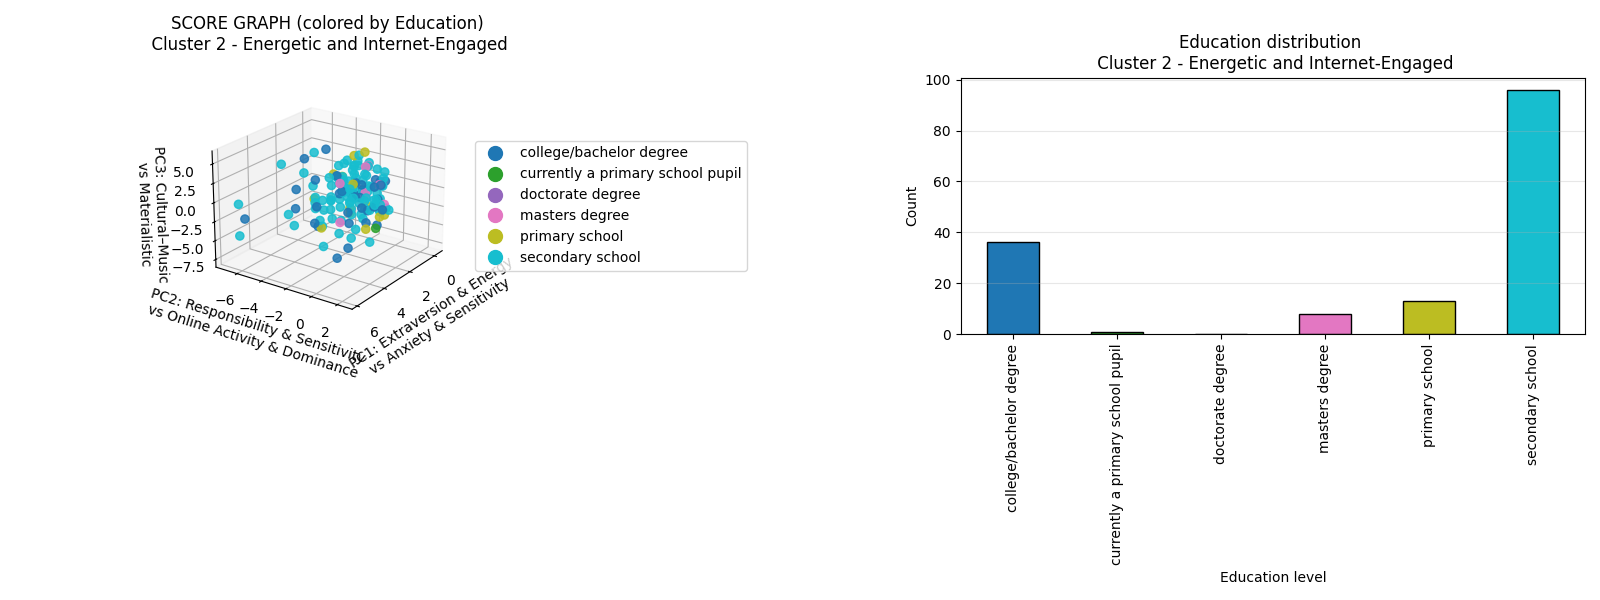


Cluster 2 – Education percentages:
Education
college/bachelor degree             23.376623
currently a primary school pupil     0.649351
doctorate degree                          NaN
masters degree                       5.194805
primary school                       8.441558
secondary school                    62.337662
Name: proportion, dtype: float64

------------------------------------------------------------



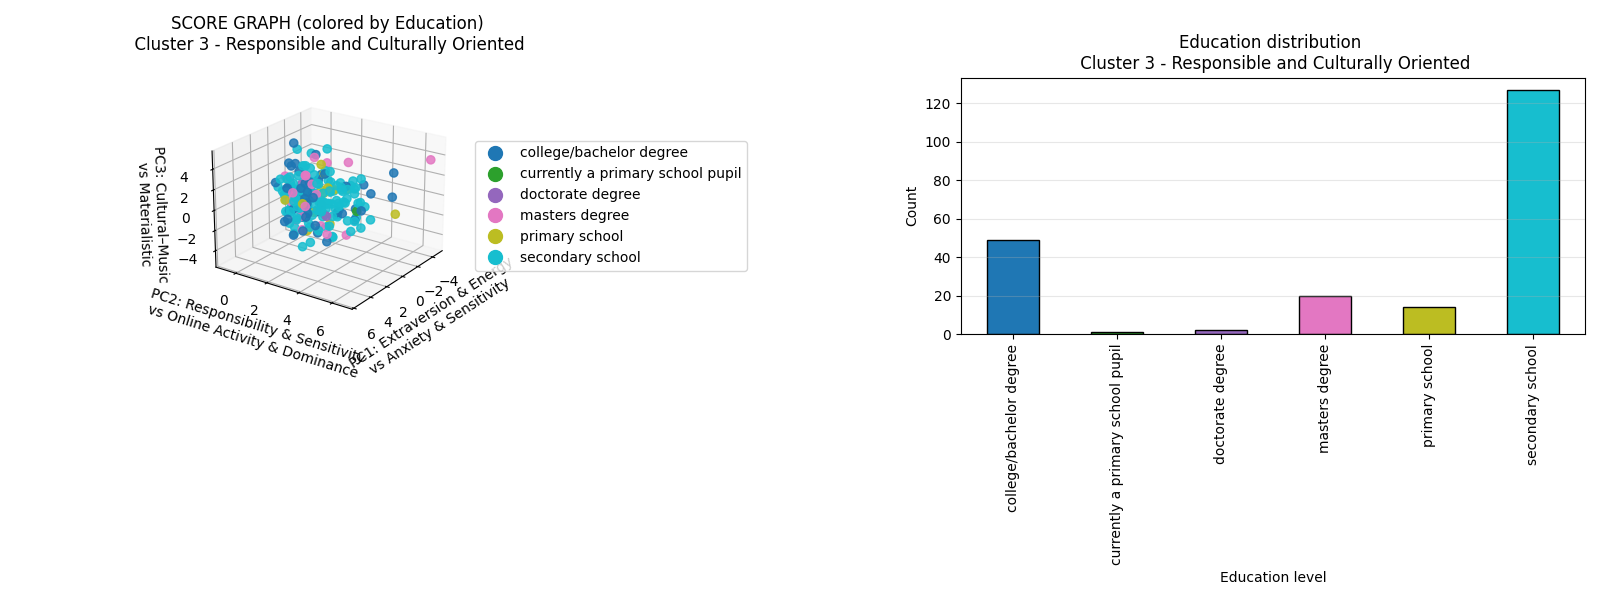


Cluster 3 – Education percentages:
Education
college/bachelor degree             23.004695
currently a primary school pupil     0.469484
doctorate degree                     0.938967
masters degree                       9.389671
primary school                       6.572770
secondary school                    59.624413
Name: proportion, dtype: float64

------------------------------------------------------------



In [14]:
education = responses_lb["Education"]

#palette discreta con 4 categorie (ordine preservato)
unique_ed = sorted(education.unique())
#unique_ed=["college/bachelor","currently primary school", "doctorate degree","masters degree", "primary school", "secondary school"]
colors_ed = plt.cm.tab10(np.linspace(0, 1, len(unique_ed)))

# mappa categoria → colore
color_map_ed = {cat: colors_ed[i] for i, cat in enumerate(unique_ed)}
fig = plt.figure(figsize=(18, 8))

# LEFT: SCORE GRAPH 3D
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
education_colors = education.map(color_map_ed)

ax1.scatter(
    Y[:, 0], Y[:, 1], Y[:, 2],
    c=education_colors, s=35, alpha=0.85
)

ax1.set_title("SCORE GRAPH colored by Education", pad=20)
ax1.set_xlabel("Extraversion & Energy\nvs Anxiety & Sensitivity")
ax1.set_ylabel("Responsibility & Sensitivity\nvs Online Activity & Dominance")
ax1.set_zlabel("Cultural–Music\nvs Materialistic")

# ----- LEGENDA ESTERNA -----
handles = [
    plt.Line2D([], [], marker='o', linestyle='', color=color_map_ed[cat],
               label=cat, markersize=10)
    for cat in unique_ed
]

ax1.legend(
    handles=handles,
    loc="center left",
    bbox_to_anchor=(1.05, 0.5),
    frameon=True
)

#ax1.view_init(elev=20, azim=45)

# RIGHT: HISTOGRAM
ax2 = fig.add_subplot(1, 2, 2)
education.value_counts().reindex(unique_ed).plot(
    kind="bar",
    color=[color_map_ed[cat] for cat in unique_ed],
    edgecolor="black",
    ax=ax2
)

ax2.set_title("Education distribution in dataset")
ax2.set_xlabel("Education level")
ax2.set_ylabel("Count")
ax2.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print(education.value_counts(normalize=True).reindex(unique_ed) * 100)


n_clusters = km.n_clusters  # = 3
print("\n" + "-"*60 + "\n")

for k in range(n_clusters):

    mask_ck = (clusters == k)
    Y_ck = Y[mask_ck]
    ed_ck = responses_lb.loc[mask_ck, "Education"]
    ed_colors_ck = ed_ck.map(color_map_ed)

    fig = plt.figure(figsize=(16, 6))

    # LEFT: SCORE GRAPH
    ax1 = fig.add_subplot(1, 2, 1, projection='3d')

    ax1.scatter(
        Y_ck[:, 0], Y_ck[:, 1], Y_ck[:, 2],
        c=ed_colors_ck, s=35, alpha=0.85
    )

    ax1.set_title(f"SCORE GRAPH (colored by Education)\n  Cluster {k+1} - {centroid_names[k]} ", pad=20)

    ax1.set_xlabel("PC1: Extraversion & Energy\nvs Anxiety & Sensitivity")
    ax1.set_ylabel("PC2: Responsibility & Sensitivity\nvs Online Activity & Dominance")
    ax1.set_zlabel("PC3: Cultural–Music\nvs Materialistic")

    # ----- LEGENDA ESTERNA -----
    handles = [
        plt.Line2D([], [], marker='o', linestyle='', color=color_map_ed[cat],
                   label=cat, markersize=10)
        for cat in unique_ed
    ]
    ax1.legend(
        handles=handles,
        loc="center left",
        bbox_to_anchor=(1.05, 0.5),
        frameon=True
    )

    ax1.view_init(elev=22, azim=35)

    # RIGHT: HISTOGRAM
    ax2 = fig.add_subplot(1, 2, 2)
    ed_ck.value_counts().reindex(unique_ed).plot(
        kind="bar",
        color=[color_map_ed[cat] for cat in unique_ed],
        edgecolor="black",
        ax=ax2
    )

    ax2.set_title(f"Education distribution \n Cluster {k+1} - {centroid_names[k]}")
    ax2.set_xlabel("Education level")
    ax2.set_ylabel("Count")
    ax2.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

    print(f"\nCluster {k+1} – Education percentages:")
    print(ed_ck.value_counts(normalize=True).reindex(unique_ed) * 100)
    print("\n" + "-"*60 + "\n")

The education label shows limited discriminative power, as the dataset is strongly **biased** toward students, with most respondents reporting secondary school as their highest level of education. This is expected, since the survey was conducted mainly among university students.
**Cluster 1** (Anxious and Digitally Absorbed Individuals) closely follows the overall distribution, with a slightly higher proportion of individuals with primary school education.
**Cluster 2** (Socially Energetic and Internet-Engaged Profile) mirrors the dataset baseline, showing no relevant deviations.
**Cluster 3** (Responsible and Culturally Oriented Profile) exhibits a slightly lower proportion of primary school education and a marginally higher presence of **master’s degrees**.

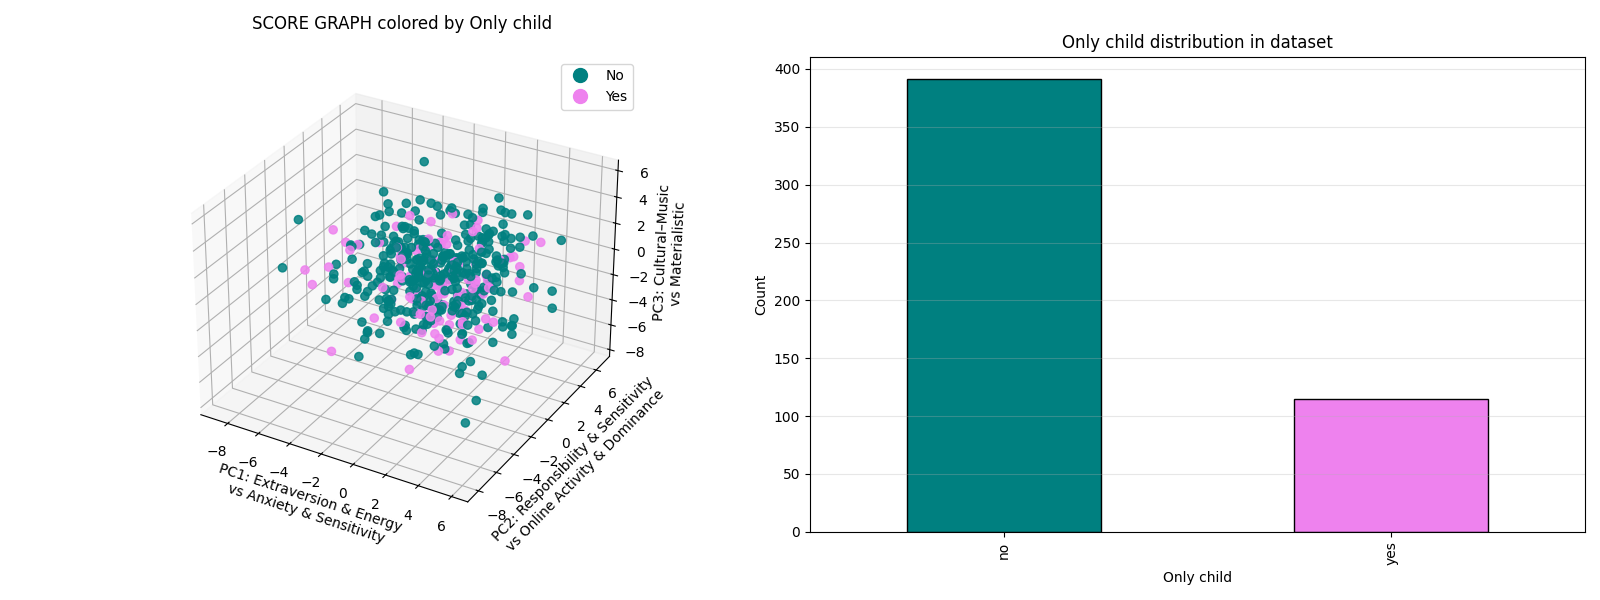

Only child
no     77.272727
yes    22.727273
Name: proportion, dtype: float64


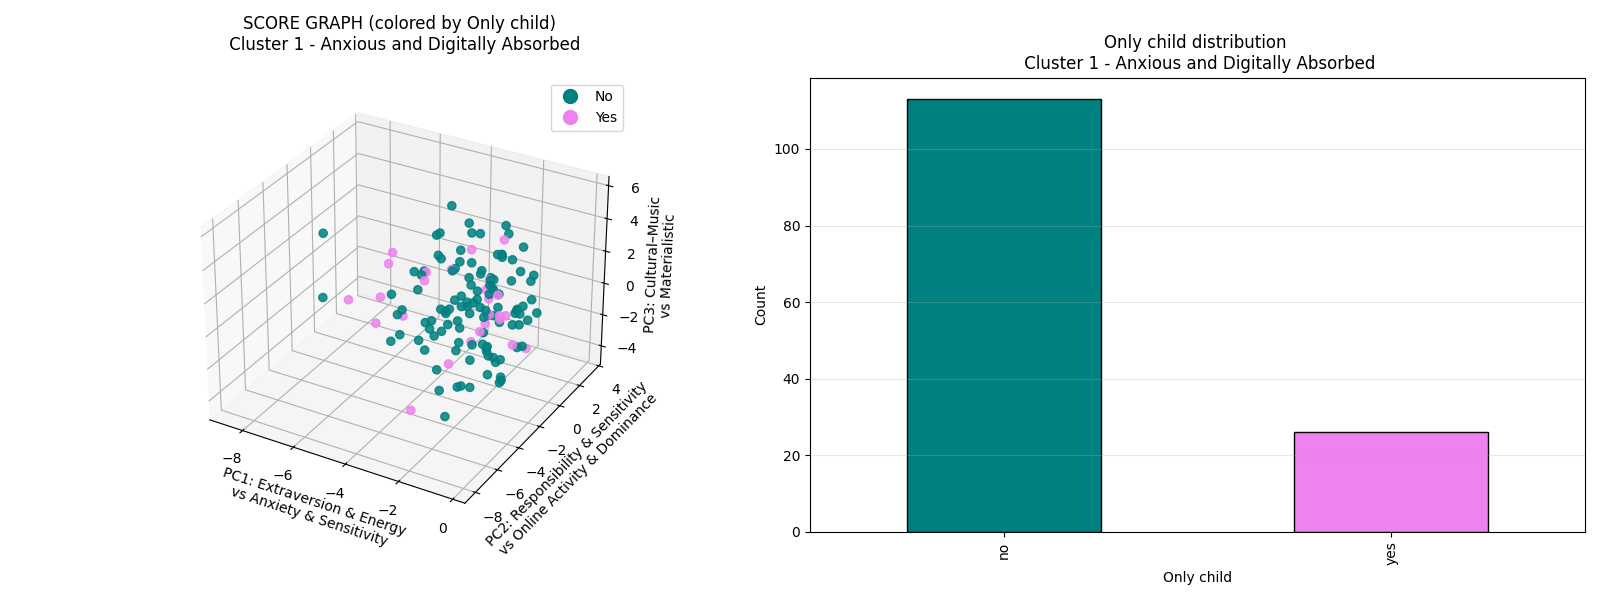


Cluster 1 – Only child percentages:
Only child
no     81.294964
yes    18.705036
Name: proportion, dtype: float64

------------------------------------------------------------



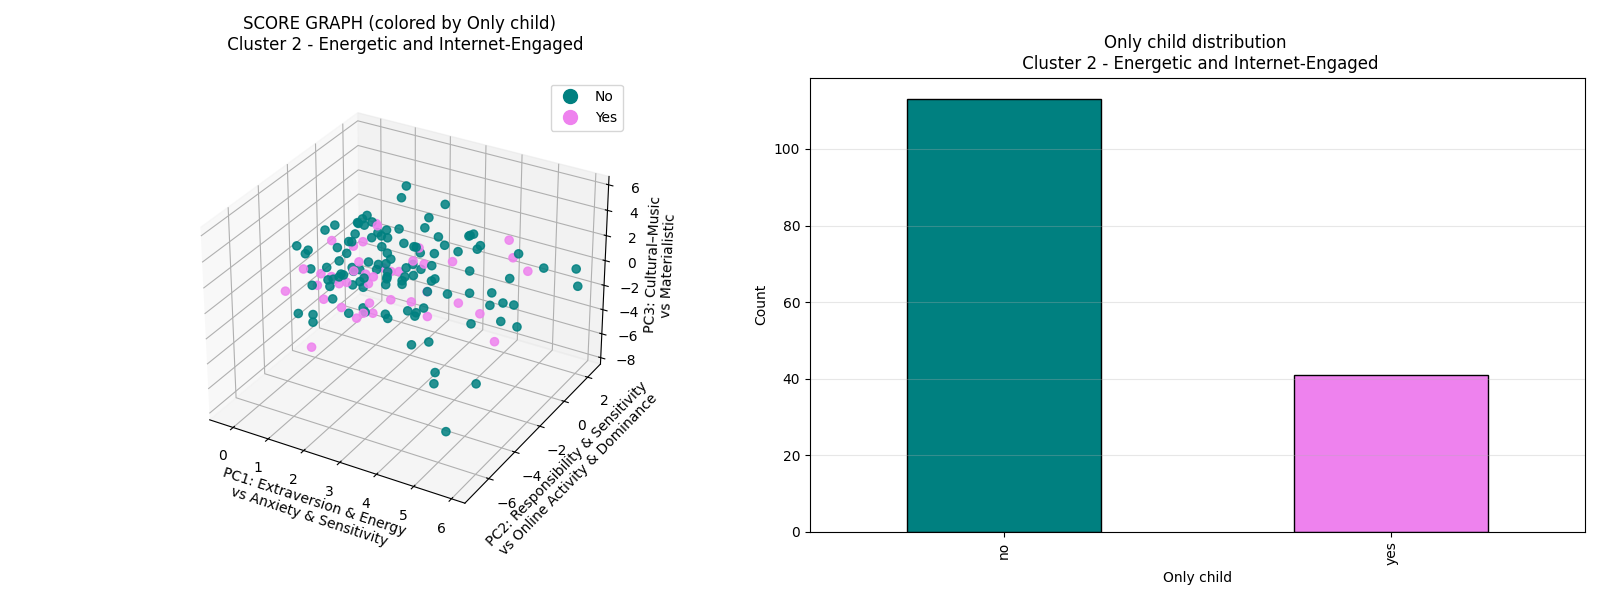


Cluster 2 – Only child percentages:
Only child
no     73.376623
yes    26.623377
Name: proportion, dtype: float64

------------------------------------------------------------



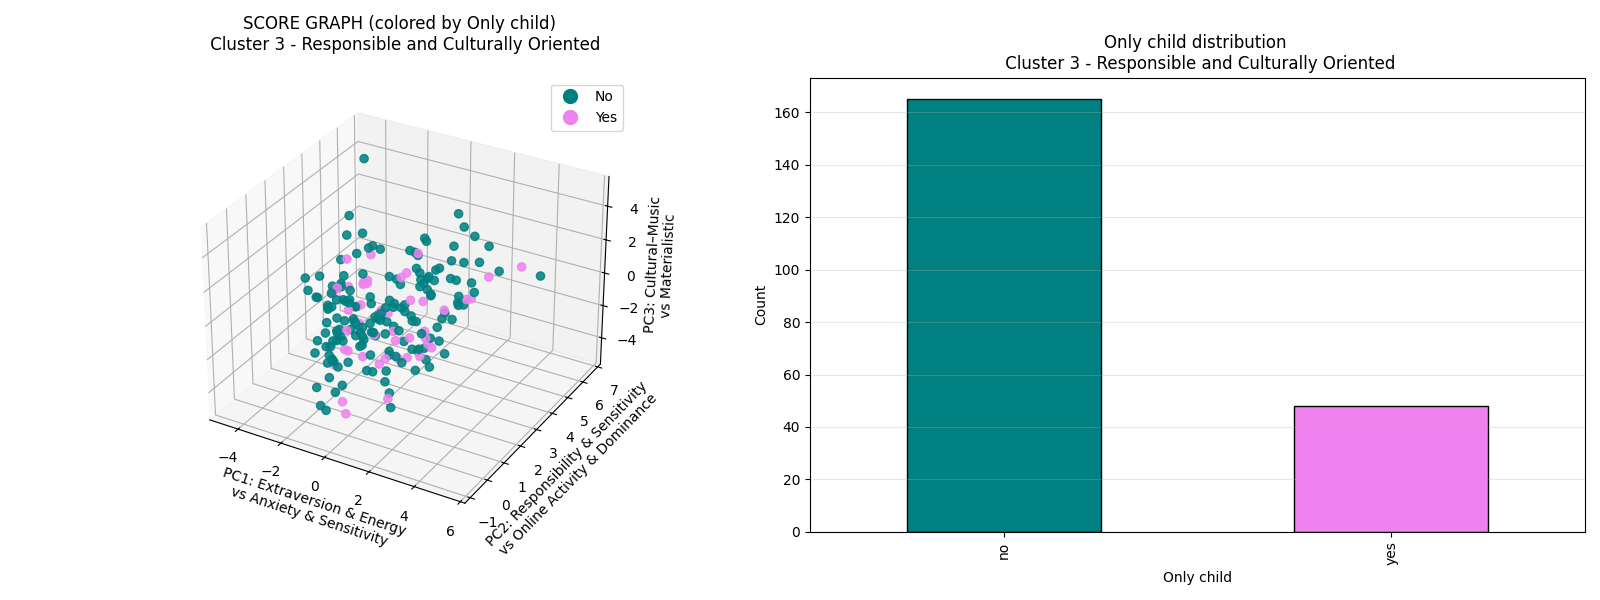


Cluster 3 – Only child percentages:
Only child
no     77.464789
yes    22.535211
Name: proportion, dtype: float64

------------------------------------------------------------



In [15]:
only_child = responses_lb["Only child"]

# ordine logico e colori coerenti
order_only = ["no", "yes"]
color_map_only = {"no": "teal", "yes": "violet"}
colors_only = [color_map_only[v] for v in order_only]
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(16, 6))

# LEFT: SCORE GRAPH 3D
ax1 = fig.add_subplot(1, 2, 1, projection='3d')

only_colors = only_child.map(color_map_only)

ax1.scatter(
    Y[:, 0], Y[:, 1], Y[:, 2],
    c=only_colors,
    s=35,
    alpha=0.85
)

ax1.set_title("SCORE GRAPH colored by Only child", pad=20)
ax1.set_xlabel("PC1: Extraversion & Energy\nvs Anxiety & Sensitivity")
ax1.set_ylabel("PC2: Responsibility & Sensitivity\nvs Online Activity & Dominance")
ax1.set_zlabel("PC3: Cultural–Music\nvs Materialistic")

# legenda esterna
handles = [
    plt.Line2D([], [], marker='o', linestyle='', color=color_map_only[v],
               label=v.capitalize(), markersize=10)
    for v in order_only
]
ax1.legend(
    handles=handles,
    loc="upper right",
    #bbox_to_anchor=(1.05, 0.5),
    #frameon=True
)

#ax1.view_init(elev=22, azim=35)

# RIGHT: HISTOGRAM
ax2 = fig.add_subplot(1, 2, 2)

only_child.value_counts().reindex(order_only).plot(
    kind="bar",
    color=colors_only,
    edgecolor="black",
    ax=ax2
)

ax2.set_title("Only child distribution in dataset")
ax2.set_xlabel("Only child")
ax2.set_ylabel("Count")
ax2.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print(only_child.value_counts(normalize=True).reindex(order_only) * 100)
n_clusters = km.n_clusters  # = 3

for k in range(n_clusters):

    mask_ck = (clusters == k)

    Y_ck = Y[mask_ck]
    only_ck = responses_lb.loc[mask_ck, "Only child"]
    only_colors_ck = only_ck.map(color_map_only)

    fig = plt.figure(figsize=(16, 6))

    # LEFT: SCORE GRAPH
    ax1 = fig.add_subplot(1, 2, 1, projection='3d')

    ax1.scatter(
        Y_ck[:, 0], Y_ck[:, 1], Y_ck[:, 2],
        c=only_colors_ck,
        s=35,
        alpha=0.85
    )

    ax1.set_title(f"SCORE GRAPH (colored by Only child) \n Cluster {k+1} - {centroid_names[k]}", pad=20)
    ax1.set_xlabel("PC1: Extraversion & Energy\nvs Anxiety & Sensitivity")
    ax1.set_ylabel("PC2: Responsibility & Sensitivity\nvs Online Activity & Dominance")
    ax1.set_zlabel("PC3: Cultural–Music\nvs Materialistic")

    handles = [
        plt.Line2D([], [], marker='o', linestyle='', color=color_map_only[v],
                   label=v.capitalize(), markersize=10)
        for v in order_only
    ]
    ax1.legend(
        handles=handles,
        loc="upper right",
        #bbox_to_anchor=(1.05, 0.5),
        #frameon=True
    )

    #ax1.view_init(elev=22, azim=35)

    # RIGHT: HISTOGRAM
    ax2 = fig.add_subplot(1, 2, 2)

    only_ck.value_counts().reindex(order_only).plot(
        kind="bar",
        color=colors_only,
        edgecolor="black",
        ax=ax2
    )

    ax2.set_title(f"Only child distribution \n Cluster {k+1} - {centroid_names[k]}")
    ax2.set_xlabel("Only child")
    ax2.set_ylabel("Count")
    ax2.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

    print(f"\nCluster {k+1} – Only child percentages:")
    print(only_ck.value_counts(normalize=True).reindex(order_only) * 100)
    print("\n" + "-"*60 + "\n")

#### For each selected label, comment the results observed in the visualizations (max 100 words per label):

**Gender**

Evaluating the clusters with respect to the external gender label reveals a clear pattern. **Cluster 2** is predominantly **male**, aligning with the *Socially Energetic and Internet-Engaged* profile. This group reflects traits like high extroversion, energy and strong internet usage, which are more prevalent among male respondents. Conversely, **Cluster 3** is largely **female**, corresponding to the *Responsible and Culturally Oriented* profile, characterized by responsibility and cultural interests more frequently observed in women. **Cluster 1** shows a slight female over-representation (67% vs 60% overall), indicating much **weaker gender-based differentiation**. Overall, these results confirm that gender significantly correlates with the behavioral profiles identified by the clustering.

**Educational Level Achieved**

The education label shows limited discriminative power, as the dataset is strongly **biased** toward students, with most respondents reporting secondary school as their highest level of education. This is expected, since the survey was conducted mainly among university students. **Cluster 1** (*Anxious and Digitally Absorbed*) closely follows the overall distribution, with a slightly higher proportion of individuals with primary school education. **Cluster 2** (*Socially Energetic and Internet-Engaged* ) mirrors the dataset baseline, showing no relevant deviations. **Cluster 3** (*Responsible and Culturally Oriented*) exhibits a slightly lower proportion of primary school education and a marginally higher presence of master’s degrees.

**Only Child**

Overall, the Only Child label shows limited discriminative power, but some mild patterns can be observed. **Cluster 1** (*Anxious and Digitally Absorbed*) shows a slightly higher proportion of individuals with siblings, suggesting that anxiety- and sensitivity-related traits are more prevalent among respondents who are not only children. **Cluster 2** (*Socially Energetic and Internet-Engaged*) presents a mildly higher proportion of only children, suggesting a stronger extroversion and social activity. **Cluster 3** (*Responsible and Culturally Oriented*) closely follows the dataset baseline, indicating no clear association between family structure and responsibility- or culture-oriented traits.

## Exercise 6. Cluster Internal Evaluations

In this exercise, you have to do the following operations:
1. For each cluster, measure the corresponding average silhouette score
1. Visualize the silhouette of the clusters and the general one of the clustering and compare them


#### Write the code for computing the silhouette scores and for visualizing them:

,Sil. Score
Anxious & Digitally Absorbed,0.126292
Energetic & Internet-Engaged,0.167989
Responsible & Culture Oriented,0.161835
Global,0.153944


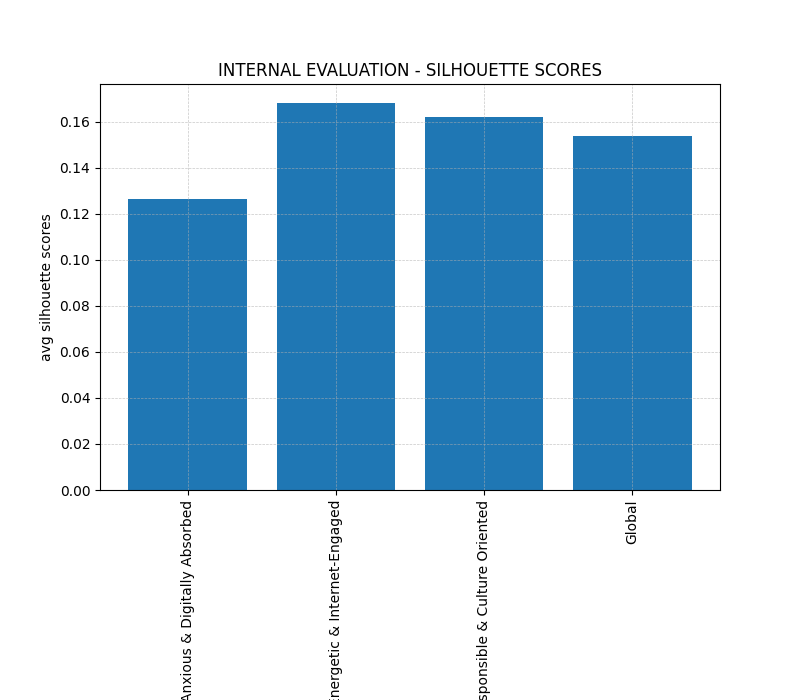

In [26]:
from sklearn.metrics import silhouette_score, silhouette_samples
silcoeff=silhouette_score(Y, km.labels_)
silscores= silhouette_samples(Y, km.labels_)
cluster_silscores=[np.mean(silscores[km.labels_==kk]) for kk in range(best_k)]

centroid_names=["Anxious & Digitally Absorbed", "Energetic & Internet-Engaged","Responsible & Culture Oriented"]

silcoeffs_df=pd.DataFrame(np.array(cluster_silscores+ [silcoeff]),index=centroid_names + ['Global'], columns=['Sil. Score'])
display(silcoeffs_df)

plt.figure(figsize=(8,7))
plt.bar(silcoeffs_df.index.tolist(), silcoeffs_df['Sil. Score'].values)
plt.xticks(silcoeffs_df.index.tolist(),rotation=90)
plt.xlabel('Data')
plt.ylabel('avg silhouette scores')
plt.title('INTERNAL EVALUATION - SILHOUETTE SCORES')
plt.grid(True, linestyle="--", linewidth=0.5, alpha=0.7)
plt.subplots_adjust(bottom=0.30)
plt.show()

#### Comment the results, also considering the results observed previously (e.g., score graphs, centroids, etc. - max 150 words):

The overall silhouette score is relatively low (0.154) compared to its theoretical range [-1, 1]. However, **this does not indicate highly dispersed or poorly formed clusters**, but rather **limited separation between their centroids**. The original dataset is very **compact** in the PCA space, as observed in the score plots, resulting in clusters that are **internally cohesive** but **only weakly separated.** Among the three groups, the ***Anxious and Digitally Absorbed*** cluster exhibits a slightly lower silhouette value, suggesting greater **internal heterogeneity**, consistent with its broader spread across multiple principal components visible in its score graph. Conversely, the ***Energetic and Internet-Engaged*** cluster achieves the highest silhouette score and appears as the **most compact group**. Overall, the low silhouette score reflects poor cluster separability, indicating that the underlying behavioural patterns vary continuously rather than forming sharply separated groups.